# Fase 2 — Machine Learning clásico: LR, RF y XGBoost (IroSvA)

**Nested CV 5×3 agrupada · TF-IDF 10k + 9 rasgos lingüísticos · F1-Macro · test oficial con 5 semillas · interpretabilidad con SHAP**

Evaluación con `StratifiedGroupKFold` y F1-Macro, con separación estricta entre selección interna y evaluación externa. Outer CV = 5 folds; Inner CV = 3 folds. LR y RF se ajustan con `GridSearchCV`; XGBoost, con Optuna (TPE, 50 trials por Outer Fold). La selección final sobre todo el train usa una CV agrupada de 3 folds.

En el test oficial, cada modelo final se entrena con **5 semillas** (42, 52, 62, 72, 82), las mismas de los Transformers, sin cambiar sus hiperparámetros, y se reporta media ± desviación. Al final, SHAP muestra qué palabras y rasgos lingüísticos influyen más en cada variante.

## 1. Librerías y entorno

Importaciones, stopwords NLTK y versiones de los paquetes utilizados.

In [4]:
import json
import time
import html
import warnings
from datetime import datetime
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import optuna
import sklearn
import xgboost
import nltk
from nltk.corpus import stopwords
from IPython.display import display, HTML, Image

from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_val_score
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
)
from xgboost import XGBClassifier

# Lista original del notebook LR/RF. Se usa la misma para los tres modelos.
try:
    STOP_WORDS = stopwords.words("spanish")
except LookupError:
    if not nltk.download("stopwords", quiet=True):
        raise RuntimeError(
            "Instala el corpus NLTK de stopwords para reproducir el TF-IDF original."
        )
    STOP_WORDS = stopwords.words("spanish")

optuna.logging.set_verbosity(optuna.logging.WARNING)

VERSIONES = {
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "sklearn": sklearn.__version__,
    "xgboost": xgboost.__version__,
    "optuna": optuna.__version__,
}
print("Versiones:", " | ".join(f"{k} {v}" for k, v in VERSIONES.items()))

import matplotlib
import matplotlib.pyplot as plt

Versiones: numpy 1.26.4 | pandas 3.0.3 | sklearn 1.8.0 | xgboost 3.2.0 | optuna 5.0.0


## 2. Configuración

Rutas, modo de ejecución, parámetros del protocolo y el panel de seguimiento se definen una sola vez en esta celda. El panel es el mismo de los notebooks de Transformers: al terminar cada etapa (Nested CV de LR/RF, Nested CV de XGBoost y búsqueda final) pasa a **verde con «✅ TERMINADO»**, imprime la hora y suena un aviso en Windows (`AVISO_SONORO`); si se detiene, pasa a **rojo con «❌ DETENIDO»**.

- `MODO="prueba"`: valida rápidamente todo el pipeline (solo MX, Nested 2×2 y 2 trials de XGBoost). Sus resultados quedan aislados en `../data/resultados_ml_groupcv_tfidf_lr_rf_10k/prueba/`.
- `MODO="completo"`: experimento definitivo 5×3; escribe en `../data/resultados_ml_groupcv_tfidf_lr_rf_10k/`.

El test oficial solo puede ejecutarse en modo completo, con `EJECUTAR_TEST_OFICIAL=True` y `CONFIRMACION_TEST="TEST_OFICIAL_CONGELADO"`.

In [5]:
DATA_DIR = Path("../data")
RANDOM_STATE = 42
MODELOS_LR_RF = ["LR", "RF"]
PREPROCESAMIENTOS = {"normal": "", "stem": "_stem", "lemma": "_lemma"}
FEATURE_COLS = ["n_exc", "n_int", "n_may", "n_emo", "n_ris", "n_neg", "n_elo", "n_com", "n_pun"]

# ------------------------------------------------------------
# "prueba" valida rápidamente todo el pipeline.
# "completo" = experimento definitivo 5×3.
# ------------------------------------------------------------
MODO = "completo"

if MODO == "prueba":
    VARIANTES = ["mx"]
    N_OUTER = 2
    N_INNER = 2
    N_TRIALS_NESTED = 2
    N_TRIALS_FINAL = 2
elif MODO == "completo":
    VARIANTES = ["mx", "es", "cu"]
    N_OUTER = 5
    N_INNER = 3
    N_TRIALS_NESTED = 50
    N_TRIALS_FINAL = 50
else:
    raise ValueError("MODO debe ser 'prueba' o 'completo'.")

# Los resultados de prueba quedan aislados en su propia subcarpeta.
OUT_DIR = DATA_DIR / "resultados_ml_groupcv_tfidf_lr_rf_10k"
if MODO == "prueba":
    OUT_DIR = OUT_DIR / "prueba"
MODELS_DIR = OUT_DIR / "modelos_finales"
for carpeta in [OUT_DIR, MODELS_DIR]:
    carpeta.mkdir(parents=True, exist_ok=True)

N_JOBS_GRID = -1  # Paralelismo de GridSearchCV para LR/RF
N_JOBS_XGB = -1  # Dentro de XGBoost; CV de Optuna secuencial

# Esta corrida fija el PERFIL ORIGINAL de LR/RF en los tres algoritmos.
# Los n-gramas se escogen INTERNAMENTE (1,1) vs (1,2), no con Outer Test.
NGRAMAS_OPCIONES = {"uni": (1, 1), "uni_bi": (1, 2)}
TFIDF_PERFIL = "LR_RF_ORIGINAL_10K_STOPWORDS_ES_NGRAMAS_INNER"

# Test oficial: solo con el protocolo congelado y en modo completo.
EJECUTAR_TEST_OFICIAL = False
CONFIRMACION_TEST = ""

# Semillas del test oficial (las mismas de los Transformers) e interpretabilidad
SEMILLAS_FINALES = [42, 52, 62, 72, 82]  # la primera debe ser RANDOM_STATE
MODELOS_ML = ["LR", "RF", "XGBoost"]
MIN_TEXTOS_PALABRA = 5  # una palabra entra al análisis global si aparece en ≥ 5 tuits del test
TOP_PALABRAS = 8  # palabras por sentido (irónico / no irónico) en la figura de SHAP

OOF_REGISTROS = []  # Predicciones independientes del Outer Test (sin datos oficiales de test)

print(f"[CONFIG][ML] modo={MODO} | variantes={VARIANTES} | algoritmos=LR, RF, XGBoost")
print(
    f"[CONFIG][ML] Nested={N_OUTER}×{N_INNER} | XGBoost trials={N_TRIALS_NESTED} por Outer (final={N_TRIALS_FINAL})"
)
print(f"[CONFIG][ML] TF-IDF={TFIDF_PERFIL} | n-gramas={NGRAMAS_OPCIONES}")
print(f"[CONFIG][ML] stopwords NLTK={len(STOP_WORDS)} | test oficial={EJECUTAR_TEST_OFICIAL}")
print(f"[CONFIG][ML] OUT_DIR={OUT_DIR.resolve()}")

# Seguimiento: panel de progreso común a todos los notebooks de modelos.
NOMBRE_EXPERIMENTO = "ML"
HEARTBEAT_SEGUNDOS = 30
# Pitido de Windows al terminar o detenerse una etapa larga (False para desactivarlo).
AVISO_SONORO = True


class Monitor:
    """Panel único de progreso + monitor.log, con estado activo / terminado / error.

    Clase común a todos los notebooks de modelos (ML, Hard Voting y Transformers).
    """

    def __init__(self, ruta, total, ya_completados=0, unidad="Fine-tunings completados"):
        self.ruta = Path(ruta)
        self.ruta.mkdir(parents=True, exist_ok=True)
        self.log = self.ruta / "monitor.log"
        self.total = int(total)
        self.unidad = unidad
        self.completados = int(ya_completados)
        self.completados_inicio = int(ya_completados)
        self.inicio = time.monotonic()
        self.ultimo_pulso = 0
        self.etapa = "Inicializando"
        self.estado = "activo"  # activo | terminado | error
        self.handle = display(HTML(f"<b>Preparando {NOMBRE_EXPERIMENTO}...</b>"), display_id=True)
        self.mostrar(forzar=True)

    def registrar(self, msg):
        with self.log.open("a", encoding="utf-8") as f:
            f.write(f"[{datetime.now():%Y-%m-%d %H:%M:%S}] {msg}\n")

    def mostrar(self, etapa=None, forzar=False):
        if etapa is not None:
            self.etapa = str(etapa)
        ahora = time.monotonic()
        if not forzar and ahora - self.ultimo_pulso < HEARTBEAT_SEGUNDOS:
            return
        self.ultimo_pulso = ahora
        minutos = (ahora - self.inicio) / 60
        hechos_sesion = self.completados - self.completados_inicio
        faltan = max(0, self.total - self.completados)
        eta = (
            f"~{minutos / hechos_sesion * faltan:.0f} min"
            if hechos_sesion >= 2
            else "calculando..."
        )
        marca = datetime.now().strftime("%H:%M:%S")
        color, titulo = {
            "activo": ("#777", f"{NOMBRE_EXPERIMENTO} — seguimiento en vivo"),
            "terminado": ("#2e7d32", f"✅ {NOMBRE_EXPERIMENTO} — TERMINADO"),
            "error": ("#c62828", f"❌ {NOMBRE_EXPERIMENTO} — DETENIDO"),
        }[self.estado]
        grosor = 1 if self.estado == "activo" else 3
        tiempo = (
            f"Tiempo: {minutos:.1f} min | ETA orientativo: {eta}"
            if self.estado == "activo"
            else f"Duración total: {minutos:.1f} min | Finalizó a las {marca}"
        )
        panel = (
            f'<div style="font-family:system-ui;padding:12px;border:{grosor}px solid {color};'
            'border-radius:8px;max-width:800px">'
            f'<b style="color:{color}">{titulo}</b><br>'
            f"Etapa: <b>{html.escape(self.etapa)}</b><br>"
            f"{self.unidad}: {self.completados}/{self.total} "
            f"({100*self.completados/max(1,self.total):.1f}%)<br>"
            f'<progress value="{self.completados}" max="{max(1,self.total)}" '
            'style="width:100%"></progress><br>'
            f"{tiempo}<br>"
            f"Última señal: {marca}<br>Log: {html.escape(str(self.log))}</div>"
        )
        self.handle.update(HTML(panel))

    def iniciar(self, msg):
        self.registrar(msg)
        self.mostrar(etapa=msg, forzar=True)

    def pulso(self):
        if time.monotonic() - self.ultimo_pulso >= HEARTBEAT_SEGUNDOS:
            self.registrar("ACTIVO: " + self.etapa)
            self.mostrar(forzar=True)

    def fit_terminado(self, msg):
        self.completados += 1
        self.registrar(msg)
        self.mostrar(etapa=msg, forzar=True)

    def finalizar(self, msg):
        """Etapa terminada: panel verde al 100 %, mensaje en la celda y aviso sonoro."""
        self.registrar(f"FINALIZADO: {msg} ({self.completados}/{self.total} contados)")
        self.estado = "terminado"
        self.completados = max(self.completados, self.total)
        self.mostrar(etapa=msg, forzar=True)
        print(f"\n✅ [{NOMBRE_EXPERIMENTO}] {msg} — {datetime.now():%Y-%m-%d %H:%M:%S}", flush=True)
        avisar_fin(ok=True)

    def fallar(self, msg):
        """Etapa detenida (error o interrupción): panel rojo, mensaje en la celda y aviso sonoro."""
        self.registrar(f"DETENIDO: {msg}")
        self.estado = "error"
        self.mostrar(etapa=msg, forzar=True)
        print(f"\n❌ [{NOMBRE_EXPERIMENTO}] {msg} — {datetime.now():%Y-%m-%d %H:%M:%S}", flush=True)
        avisar_fin(ok=False)


def avisar_fin(ok=True):
    """Pitido de Windows al terminar (3 veces) o al detenerse (1 vez); en otros sistemas no hace nada."""
    if not AVISO_SONORO:
        return
    try:
        import winsound

        for _ in range(3 if ok else 1):
            winsound.MessageBeep(winsound.MB_ICONASTERISK if ok else winsound.MB_ICONHAND)
            time.sleep(0.5)
    except Exception:
        pass

[CONFIG][ML] modo=completo | variantes=['mx', 'es', 'cu'] | algoritmos=LR, RF, XGBoost
[CONFIG][ML] Nested=5×3 | XGBoost trials=50 por Outer (final=50)
[CONFIG][ML] TF-IDF=LR_RF_ORIGINAL_10K_STOPWORDS_ES_NGRAMAS_INNER | n-gramas={'uni': (1, 1), 'uni_bi': (1, 2)}
[CONFIG][ML] stopwords NLTK=313 | test oficial=False
[CONFIG][ML] OUT_DIR=C:\Users\I21309\Documents\DeteccionDeSarcasmo\data\resultados_ml_groupcv_tfidf_lr_rf_10k


## 3. Integridad de los CSV y validación por grupos

Los CSV provienen de `01_preprocesamiento_ML.ipynb`. Ese notebook, dentro del train de cada variante, retira todas las apariciones de textos con etiquetas contradictorias y deja una sola copia de los textos repetidos con la misma etiqueta (coincidencia exacta de `MESSAGE`). El test oficial **no** se usa para eliminar registros del train; las coincidencias train ↔ test no se eliminan del train: `06_Comparacion_final.ipynb` las excluye del resultado principal del test y reporta además el test completo (análisis de sensibilidad).

Este notebook tampoco compara ni elimina filas contra el test oficial.

Aquí se verifica únicamente:

- alineación entre `normal`, `stem` y `lemma` (mismo número de filas, mismas etiquetas y mismas columnas `ID`/`MESSAGE`);
- rasgos lingüísticos idénticos entre las tres representaciones;
- construcción de un identificador de grupo por fila (se guarda en `GRUPOS_TRAIN`, no como columna del CSV): dos filas quedan en el mismo grupo si coinciden, tras `casefold()` y `strip()`, en el texto `normal`, `stem` o `lemma`, o en el `MESSAGE` original; la unión es transitiva (componentes conexos). Las etiquetas no intervienen en la agrupación;
- ausencia de grupos compartidos entre train y validación en los splits Outer, Inner y en los de la búsqueda final.

Los grupos con etiquetas contradictorias se conservan sin modificar y se exportan a `auditoria_etiquetas_contradictorias.csv`. `StratifiedGroupKFold` mantiene cada grupo completo dentro de un solo lado del split.

In [6]:
# ============================================================
# 3. CARGA, INTEGRIDAD Y GRUPOS SIN FUGA ENTRE FOLDS
# ============================================================
GRUPOS_TRAIN = {}  # Variante -> np.array; solo contiene información del TRAIN
AUDITORIA_GRUPOS = []
AUDITORIA_CONFLICTOS = []
AUDITORIA_PARTICIONES = []


class UnionFind:
    """Componentes conexos: unión por rango con compresión de caminos."""

    def __init__(self, n):
        self.parent = list(range(n))
        self.rank = [0] * n

    def find(self, x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra == rb:
            return
        if self.rank[ra] < self.rank[rb]:
            ra, rb = rb, ra
        self.parent[rb] = ra
        if self.rank[ra] == self.rank[rb]:
            self.rank[ra] += 1


def cargar_split(variante, prep, split="train"):
    """Carga el CSV preprocesado de una variante, representación y split."""
    if variante not in VARIANTES or prep not in PREPROCESAMIENTOS:
        raise ValueError(f"Variante/preprocessing no reconocido: {variante}/{prep}")
    ruta = DATA_DIR / f"{split}_clean{PREPROCESAMIENTOS[prep]}_{variante}.csv"
    if not Path(ruta).is_file():
        raise FileNotFoundError(f"Falta el CSV: {ruta}")
    # Preservar los IDs originales: no forzarles una conversión numérica.
    return pd.read_csv(ruta, dtype={"ID": "string"}).reset_index(drop=True)


def preparar_xy(df):
    """Separa texto + 9 rasgos (X) y etiqueta (y)."""
    columnas = ["MESSAGE_CLEAN"] + FEATURE_COLS
    faltantes = [c for c in columnas + ["IS_IRONIC"] if c not in df.columns]
    if faltantes:
        raise ValueError(f"Faltan columnas requeridas: {faltantes}")
    X = df[columnas].copy()
    y = df["IS_IRONIC"].astype(int).reset_index(drop=True)
    X["MESSAGE_CLEAN"] = X["MESSAGE_CLEAN"].fillna("").astype(str)
    X[FEATURE_COLS] = X[FEATURE_COLS].fillna(0)
    return X.reset_index(drop=True), y


def texto_clave(serie):
    """Normalización usada solo para comparar textos al agrupar (no altera el texto del modelo)."""
    # Misma normalización de COMPARACIÓN que la auditoría previa; no modifica el texto del modelo.
    return serie.fillna("").astype(str).str.casefold().str.strip()


def construir_grupos(variante, dfs_por_prep, y):
    """Componentes conexos: agrupa un mismo texto tras normal, stem O lemma.
    No deduplica, no usa las etiquetas para construir grupos y conserva rasgos originales.
    Añade coincidencias de MESSAGE original exacto, si está disponible.
    """
    n = len(y)
    uf = UnionFind(n)

    for prep, df in dfs_por_prep.items():
        primero = {}
        for i, clave in enumerate(texto_clave(df["MESSAGE_CLEAN"])):
            if not clave:
                raise ValueError(
                    f"{variante}/{prep}: texto limpio vacío en fila {i}; revisar antes de agrupar"
                )
            if clave in primero:
                uf.union(primero[clave], i)
            else:
                primero[clave] = i
    # Si dos textos originales son idénticos, deben permanecer en el mismo grupo.
    df_ref = dfs_por_prep["normal"]
    if "MESSAGE" in df_ref:
        primero_raw = {}
        for i, clave in enumerate(texto_clave(df_ref["MESSAGE"])):
            if not clave:
                continue
            if clave in primero_raw:
                uf.union(primero_raw[clave], i)
            else:
                primero_raw[clave] = i

    miembros = {}
    for i in range(n):
        miembros.setdefault(uf.find(i), []).append(i)
    # Id de grupo basado en el menor índice original; determinista entre ambos notebooks.
    ids = {ra: min(idx) for ra, idx in miembros.items()}
    grupos = np.array([ids[uf.find(i)] for i in range(n)], dtype=int)
    duplicados = {ids[ra]: idx for ra, idx in miembros.items() if len(idx) > 1}
    conflictivos = [(g, idx) for g, idx in duplicados.items() if y.iloc[idx].nunique() > 1]
    if conflictivos:
        warnings.warn(
            f"{variante.upper()}: {len(conflictivos)} grupo(s) con etiquetas contradictorias. "
            "Se conservan las etiquetas originales y se mantienen juntos todos sus registros. "
            "Revisar manualmente antes de interpretar resultados.",
            stacklevel=2,
        )
    for g, idx in conflictivos:
        for i in idx:
            AUDITORIA_CONFLICTOS.append(
                {
                    "variante": variante,
                    "grupo": int(g),
                    "fila_0base": int(i),
                    "id_original": str(df_ref.iloc[i]["ID"]) if "ID" in df_ref else "",
                    "etiqueta": int(y.iloc[i]),
                    "texto_original": str(df_ref.iloc[i]["MESSAGE"]) if "MESSAGE" in df_ref else "",
                    "texto_normal": str(df_ref.iloc[i]["MESSAGE_CLEAN"]),
                }
            )
    AUDITORIA_GRUPOS.append(
        {
            "variante": variante,
            "n_train": n,
            "n_grupos": len(miembros),
            "n_grupos_multiples": len(duplicados),
            "n_filas_en_grupos_multiples": sum(map(len, duplicados.values())),
            "tamano_grupo_max": max(map(len, miembros.values())),
            "n_grupos_etiquetas_contradictorias": len(conflictivos),
            "criterio": "union_texto_normal_stem_lemma_y_original_exacto",
        }
    )
    return grupos


def cargar_todos_preps(variante, split="train"):
    """Carga normal/stem/lemma de una variante, verifica que estén alineados y construye los grupos."""
    dfs = {p: cargar_split(variante, p, split=split) for p in PREPROCESAMIENTOS}
    ref = dfs["normal"]
    X_ref, y_ref = preparar_xy(ref)
    datos = {"normal": X_ref}
    for prep, df in dfs.items():
        if prep == "normal":
            continue
        X, y = preparar_xy(df)
        if len(df) != len(ref) or not y.equals(y_ref):
            raise ValueError(f"{variante}/{prep}: diferente número de filas o etiquetas")
        for c in ["ID", "MESSAGE"]:
            if c in ref.columns and c not in df.columns:
                raise ValueError(f"{variante}/{prep}: falta columna de alineación {c}")
            if c in ref.columns and not ref[c].astype(str).equals(df[c].astype(str)):
                raise ValueError(f"{variante}/{prep}: columna {c} desalineada")
        if not X[FEATURE_COLS].equals(X_ref[FEATURE_COLS]):
            raise ValueError(f"{variante}/{prep}: rasgos lingüísticos no alineados")
        datos[prep] = X
    if split == "train" and variante not in GRUPOS_TRAIN:
        GRUPOS_TRAIN[variante] = construir_grupos(variante, dfs, y_ref)
    return datos, y_ref


def grupos_train(variante):
    """Devuelve los grupos del train de una variante (los construye si aún no existen)."""
    if variante not in GRUPOS_TRAIN:
        cargar_todos_preps(variante, split="train")
    return GRUPOS_TRAIN[variante]


def verificar_particion(grupos, a, b, variante, nivel, outer, inner=None):
    """Comprueba que train y validación no compartan grupos y registra la partición."""
    solapamiento = set(grupos[a]) & set(grupos[b])
    if solapamiento:
        raise AssertionError(
            f"FUGA: {variante}/{nivel}/{outer}/{inner} grupos compartidos: {solapamiento}"
        )
    AUDITORIA_PARTICIONES.append(
        {
            "variante": variante,
            "nivel": nivel,
            "outer_fold": outer,
            "inner_fold": inner,
            "n_train": len(a),
            "n_validacion": len(b),
            "n_grupos_compartidos": 0,
        }
    )


def crear_splits_outer(y, grupos, variante="?"):
    """Outer CV agrupada y estratificada."""
    cv = StratifiedGroupKFold(n_splits=N_OUTER, shuffle=True, random_state=RANDOM_STATE)
    splits = list(cv.split(np.zeros(len(y)), y, groups=grupos))
    for fold, (a, b) in enumerate(splits, 1):
        verificar_particion(grupos, a, b, variante, "outer", fold)
    return splits


def crear_splits_inner(y, grupos, outer_fold, variante="?"):
    """Inner CV agrupada dentro de un Outer Train (semilla RANDOM_STATE + outer_fold)."""
    cv = StratifiedGroupKFold(
        n_splits=N_INNER, shuffle=True, random_state=RANDOM_STATE + outer_fold
    )
    splits = list(cv.split(np.zeros(len(y)), y, groups=grupos))
    for fold, (a, b) in enumerate(splits, 1):
        verificar_particion(grupos, a, b, variante, "inner", outer_fold, fold)
    return splits


def crear_splits_final(y, grupos, variante="?"):
    """CV agrupada sobre todo el train para la búsqueda final."""
    cv = StratifiedGroupKFold(n_splits=N_INNER, shuffle=True, random_state=RANDOM_STATE)
    splits = list(cv.split(np.zeros(len(y)), y, groups=grupos))
    for fold, (a, b) in enumerate(splits, 1):
        verificar_particion(grupos, a, b, variante, "final", 0, fold)
    return splits


# ============================================================
# AUDITORÍA PREVIA — SOLO TRAIN Y FOLDS
# ============================================================
for v in VARIANTES:
    _, etiquetas = cargar_todos_preps(v, split="train")
    gv = grupos_train(v)

    for o, (a, b) in enumerate(crear_splits_outer(etiquetas, gv, v), 1):
        crear_splits_inner(etiquetas.iloc[a].reset_index(drop=True), gv[a], o, v)

    crear_splits_final(etiquetas, gv, v)


df_auditoria_grupos = pd.DataFrame(AUDITORIA_GRUPOS)

df_auditoria_particiones = pd.DataFrame(AUDITORIA_PARTICIONES).drop_duplicates()

df_auditoria_conflictos = pd.DataFrame(AUDITORIA_CONFLICTOS)

print("[AUDIT][ML] Grupos del train")
display(df_auditoria_grupos)

print("\n[AUDIT][ML] Grupos compartidos entre train y validación (todos deben ser 0):")
display(
    df_auditoria_particiones.groupby(["variante", "nivel"], as_index=False)[
        "n_grupos_compartidos"
    ].max()
)

pd.DataFrame(AUDITORIA_GRUPOS).to_csv(OUT_DIR / "auditoria_grupos.csv", index=False)

df_auditoria_particiones.to_csv(OUT_DIR / "auditoria_folds.csv", index=False)

df_auditoria_conflictos.to_csv(OUT_DIR / "auditoria_etiquetas_contradictorias.csv", index=False)

print("\nPRE-FLIGHT DE DATOS: OK")

C:\Users\I21309\AppData\Local\Temp\ipykernel_35744\914888969.py:159: UserWarning: ES: 1 grupo(s) con etiquetas contradictorias. Se conservan las etiquetas originales y se mantienen juntos todos sus registros. Revisar manualmente antes de interpretar resultados.
  GRUPOS_TRAIN[variante] = construir_grupos(variante, dfs, y_ref)


[AUDIT][ML] Grupos del train


,variante,n_train,n_grupos,n_grupos_multiples,n_filas_en_grupos_multiples,tamano_grupo_max,n_grupos_etiquetas_contradictorias,criterio
0,mx,2399,2393,3,9,5,0,union_texto_normal_stem_lemma_y_original_exacto
1,es,2397,2289,45,153,17,1,union_texto_normal_stem_lemma_y_original_exacto
2,cu,2400,2389,11,22,2,0,union_texto_normal_stem_lemma_y_original_exacto



[AUDIT][ML] Grupos compartidos entre train y validación (todos deben ser 0):


,variante,nivel,n_grupos_compartidos
0,cu,final,0
1,cu,inner,0
2,cu,outer,0
3,es,final,0
4,es,inner,0
5,es,outer,0
6,mx,final,0
7,mx,inner,0
8,mx,outer,0



PRE-FLIGHT DE DATOS: OK


## 4. TF-IDF original LR/RF, común a LR, RF y XGBoost

Se reproduce `TfidfVectorizer(stop_words=STOP_WORDS, max_features=10000)` del notebook original de LR/RF (resto de parámetros por defecto: `lowercase=True`, `min_df=1`, `max_df=1.0`, `sublinear_tf=False`), **incluyendo** la comparación `(1,1)` vs `(1,2)` dentro del Inner CV. A la matriz TF-IDF se le concatenan los nueve rasgos lingüísticos mediante `passthrough`, es decir, **sin escalar**. Todos los algoritmos tienen las mismas opciones de representación; cada uno puede elegir un rango de n-gramas diferente sin afectar la evaluación independiente del Outer Fold.

**Nota sobre stopwords:** se usa la lista NLTK de español (313 palabras) tal cual, para este experimento controlado. La lista incluye términos de negación e intensidad que pueden ser útiles en sarcasmo (por ejemplo «no», «ni», «sin», «muy», «nada»). La misma lista, en formas completas, se aplica a las tres versiones del texto, incluidas `stem` y `lemma`. Si posteriormente se evalúa otra lista, tendrá que ser otra corrida separada.

In [7]:
def crear_preprocesador_tfidf(ngram_range=(1, 1)):
    """Exactamente el TF-IDF base original LR/RF y sus 9 rasgos."""
    tfidf = TfidfVectorizer(stop_words=STOP_WORDS, max_features=10000, ngram_range=ngram_range)
    return ColumnTransformer(
        transformers=[
            ("tfidf", tfidf, "MESSAGE_CLEAN"),
            ("linguisticas", "passthrough", FEATURE_COLS),
        ],
        remainder="drop",
    )


# Única representación compartida por todos los modelos.
crear_preprocesador_lr_rf = crear_preprocesador_tfidf
crear_preprocesador_xgb = crear_preprocesador_tfidf

print(
    "[CONFIG][ML] TF-IDF: stopwords NLTK, max_features=10000, n-gramas (1,1)/(1,2) elegidos en el Inner CV."
)

[CONFIG][ML] TF-IDF: stopwords NLTK, max_features=10000, n-gramas (1,1)/(1,2) elegidos en el Inner CV.


## 5. LR y RF — GridSearchCV con TF-IDF original y preprocesamiento dentro del Inner CV

Se conservan las rejillas de hiperparámetros de los clasificadores del notebook anterior, ambos con `class_weight="balanced"`:

- **LR:** `C ∈ {0.1, 1, 10}`, `solver="liblinear"`, `max_iter=10000` (6 combinaciones con n-gramas).
- **RF:** `n_estimators ∈ {100, 200, 300}`, `max_depth ∈ {None, 10, 20}`, `min_samples_split ∈ {2, 5}` (36 combinaciones con n-gramas).

Se añade para ambos `features__tfidf__ngram_range ∈ {(1,1), (1,2)}`. En cada Outer Fold se ejecuta un `GridSearchCV` independiente para cada preprocesamiento (`normal/stem/lemma`); gana el que obtiene el mayor F1-Macro medio en el Inner CV y, en caso de empate numérico, el de menor desviación entre folds internos. El estimador ganador es el refit de `GridSearchCV` sobre todo el Outer Train. Outer Test permanece aislado.

In [8]:
def crear_pipeline_lr_rf(modelo):
    """Pipeline TF-IDF + 9 rasgos + LR o RF (class_weight='balanced')."""
    if modelo == "LR":
        clf = LogisticRegression(max_iter=10000, random_state=RANDOM_STATE, class_weight="balanced")
    elif modelo == "RF":
        clf = RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced", n_jobs=1)
    else:
        raise ValueError(f"Modelo LR/RF no reconocido: {modelo}")
    return Pipeline(steps=[("features", crear_preprocesador_lr_rf()), ("clf", clf)])


def grid_lr_rf(modelo):
    """Rejilla de GridSearchCV (incluye el rango de n-gramas)."""
    if modelo == "LR":
        grid = {"clf__C": [0.1, 1.0, 10], "clf__solver": ["liblinear"]}
    elif modelo == "RF":
        grid = {
            "clf__n_estimators": [100, 200, 300],
            "clf__max_depth": [None, 10, 20],
            "clf__min_samples_split": [2, 5],
        }
    else:
        raise ValueError(modelo)
    grid["features__tfidf__ngram_range"] = [(1, 1), (1, 2)]
    return grid


def buscar_lr_rf_train(
    X_por_prep, y, modelo, inner_splits, monitor=None, variante=None, outer_fold=None
):
    """Selecciona preprocessing + hiperparámetros EXCLUSIVAMENTE por puntuación Inner CV."""
    mejor = None
    candidatos = []
    for prep, X in X_por_prep.items():
        fase = f"Outer {outer_fold}/{N_OUTER}" if outer_fold is not None else "Final"
        etiqueta = f"[{str(variante).upper()}][{modelo}][{fase}] GridSearch | prep={prep}"
        if monitor is not None:
            monitor.iniciar(etiqueta)
        search = GridSearchCV(
            estimator=crear_pipeline_lr_rf(modelo),
            param_grid=grid_lr_rf(modelo),
            cv=inner_splits,
            scoring="f1_macro",
            n_jobs=N_JOBS_GRID,
            refit=True,
            error_score="raise",
        )
        search.fit(X, y)
        if monitor is not None:
            monitor.fit_terminado(etiqueta + " | completado")
        scores_folds = [
            search.cv_results_[f"split{i}_test_score"][search.best_index_]
            for i in range(len(inner_splits))
        ]
        desviacion = float(np.std(scores_folds, ddof=1))
        candidato = {
            "prep": prep,
            "inner_f1": float(search.best_score_),
            "inner_std": desviacion,
            "params": search.best_params_,
            "estimator": search.best_estimator_,
        }
        candidatos.append({k: v for k, v in candidato.items() if k != "estimator"})
        if (
            mejor is None
            or candidato["inner_f1"] > mejor["inner_f1"]
            or (
                np.isclose(candidato["inner_f1"], mejor["inner_f1"])
                and candidato["inner_std"] < mejor["inner_std"]
            )
        ):
            mejor = candidato
    return mejor, candidatos


def nested_cv_lr_rf_variante(variante, modelo, monitor=None):
    """Nested CV agrupada de LR o RF para una variante."""
    X_por_prep, y = cargar_todos_preps(variante, split="train")
    detalle, candidatos_inner = [], []
    grupos = grupos_train(variante)
    for outer_fold, (i_train, i_test) in enumerate(
        crear_splits_outer(y, grupos, variante), start=1
    ):
        y_train, y_test = y.iloc[i_train].reset_index(drop=True), y.iloc[i_test].reset_index(
            drop=True
        )
        X_train = {p: X.iloc[i_train].reset_index(drop=True) for p, X in X_por_prep.items()}
        X_outer = {p: X.iloc[i_test].reset_index(drop=True) for p, X in X_por_prep.items()}
        mejor, candidatos = buscar_lr_rf_train(
            X_train,
            y_train,
            modelo,
            crear_splits_inner(y_train, grupos[i_train], outer_fold, variante),
            monitor=monitor,
            variante=variante,
            outer_fold=outer_fold,
        )
        for c in candidatos:
            candidatos_inner.append(
                {
                    "variante": variante,
                    "modelo": modelo,
                    "outer_fold": outer_fold,
                    "preprocessing": c["prep"],
                    "inner_f1_macro": c["inner_f1"],
                    "inner_f1_std": c["inner_std"],
                    "best_params": c["params"],
                }
            )
        prep = mejor["prep"]
        # search.best_estimator_ ya es un refit nuevo sobre TODO este outer_train.
        estimador = mejor["estimator"]
        pred_train = estimador.predict(X_train[prep])
        pred_outer = estimador.predict(X_outer[prep])
        train_f1 = f1_score(y_train, pred_train, average="macro")
        outer_f1 = f1_score(y_test, pred_outer, average="macro")
        # Cada registro figura exactamente una vez como Outer Test en una CV 5-fold.
        OOF_REGISTROS.append(
            pd.DataFrame(
                {
                    "variante": variante,
                    "modelo": modelo,
                    "outer_fold": outer_fold,
                    "idx_train_oficial": i_test,
                    "y_true": y_test.to_numpy(),
                    "y_pred": np.asarray(pred_outer),
                }
            )
        )
        f1_clase = f1_score(y_test, pred_outer, labels=[0, 1], average=None, zero_division=0)
        detalle.append(
            {
                "variante": variante,
                "modelo": modelo,
                "outer_fold": outer_fold,
                "outer_f1_clase_0": float(f1_clase[0]),
                "outer_f1_clase_1": float(f1_clase[1]),
                "best_preprocessing": prep,
                "train_f1_macro": float(train_f1),
                "inner_best_f1": mejor["inner_f1"],
                "inner_best_std": mejor["inner_std"],
                "outer_f1_macro": float(outer_f1),
                "generalization_gap": float(train_f1 - outer_f1),
                "best_params": mejor["params"],
            }
        )
        print(
            f"[{variante.upper()}][{modelo}][Outer {outer_fold}/{N_OUTER}] FINALIZADO | "
            f"prep={prep} | F1_inner={mejor['inner_f1']:.4f}±{mejor['inner_std']:.4f} | "
            f"F1_train={train_f1:.4f} | F1_outer={outer_f1:.4f} | gap={train_f1 - outer_f1:.4f}"
        )
    return pd.DataFrame(detalle), pd.DataFrame(candidatos_inner)

### 5.1 Ejecutar Nested CV de LR y RF (solo train)

Esta celda es computacionalmente costosa: en cada uno de los 5 Outer folds evalúa todas las combinaciones de cada grid sobre los **3 Inner folds**, para las 3 alternativas de preprocesamiento. En total: 3 variantes × 5 Outer × 3 preprocesamiento × 3 Inner = 135 ajustes por combinación del grid, es decir, 810 ajustes para LR y 4 860 para RF, más un refit por búsqueda (45 por modelo). El monitor cuenta 90 búsquedas `GridSearchCV`.

In [9]:
total_bloques_lr_rf = len(VARIANTES) * len(MODELOS_LR_RF) * N_OUTER * len(PREPROCESAMIENTOS)
monitor_lr_rf = Monitor(
    OUT_DIR, total=total_bloques_lr_rf, unidad="Búsquedas GridSearch completadas"
)

resultados_nested_lr_rf = {}
registros_lr_rf = []
candidatos_inner_lr_rf = []

try:
    for variante in VARIANTES:
        for modelo in MODELOS_LR_RF:
            detalle, candidatos = nested_cv_lr_rf_variante(variante, modelo, monitor=monitor_lr_rf)
            resultados_nested_lr_rf[(variante, modelo)] = detalle
            candidatos_inner_lr_rf.append(candidatos)
            registros_lr_rf.append(
                {
                    "variante": variante,
                    "modelo": modelo,
                    "f1_train_mean": detalle["train_f1_macro"].mean(),
                    "f1_nested_mean": detalle["outer_f1_macro"].mean(),
                    "f1_nested_std": detalle["outer_f1_macro"].std(ddof=1),
                    "gap_mean": detalle["generalization_gap"].mean(),
                }
            )
except KeyboardInterrupt:
    monitor_lr_rf.fallar("Nested CV de LR/RF interrumpida")
    raise
except Exception as exc:
    monitor_lr_rf.registrar(f"ERROR {type(exc).__name__}: {exc}")
    monitor_lr_rf.fallar(
        f"Nested CV de LR/RF con error {type(exc).__name__}; consultar monitor.log"
    )
    raise

df_nested_lr_rf = pd.DataFrame(registros_lr_rf)
df_candidatos_inner_lr_rf = pd.concat(candidatos_inner_lr_rf, ignore_index=True)
monitor_lr_rf.finalizar("Nested CV de LR y RF completada")
print("\n[LR/RF] RESUMEN NESTED CV")
display(df_nested_lr_rf.round(4))

[MX][LR][Outer 1/5] FINALIZADO | prep=lemma | F1_inner=0.6421±0.0206 | F1_train=0.8932 | F1_outer=0.6291 | gap=0.2641
[MX][LR][Outer 2/5] FINALIZADO | prep=normal | F1_inner=0.6324±0.0098 | F1_train=0.9087 | F1_outer=0.6511 | gap=0.2576
[MX][LR][Outer 3/5] FINALIZADO | prep=normal | F1_inner=0.6548±0.0036 | F1_train=0.9153 | F1_outer=0.6674 | gap=0.2479
[MX][LR][Outer 4/5] FINALIZADO | prep=lemma | F1_inner=0.6440±0.0211 | F1_train=0.8856 | F1_outer=0.6403 | gap=0.2453
[MX][LR][Outer 5/5] FINALIZADO | prep=stem | F1_inner=0.6457±0.0086 | F1_train=0.8714 | F1_outer=0.6371 | gap=0.2343
[MX][RF][Outer 1/5] FINALIZADO | prep=stem | F1_inner=0.6309±0.0104 | F1_train=0.8904 | F1_outer=0.6501 | gap=0.2403
[MX][RF][Outer 2/5] FINALIZADO | prep=normal | F1_inner=0.6264±0.0086 | F1_train=0.8134 | F1_outer=0.5993 | gap=0.2141
[MX][RF][Outer 3/5] FINALIZADO | prep=normal | F1_inner=0.6400±0.0242 | F1_train=0.8018 | F1_outer=0.6319 | gap=0.1699
[MX][RF][Outer 4/5] FINALIZADO | prep=normal | F1_inne

,variante,modelo,f1_train_mean,f1_nested_mean,f1_nested_std,gap_mean
0,mx,LR,0.8948,0.6450,0.0148,0.2498
1,mx,RF,0.8221,0.6307,0.0197,0.1913
2,es,LR,0.9230,0.7024,0.0157,0.2205
3,es,RF,0.9446,0.6959,0.0298,0.2487
4,cu,LR,0.9275,0.6586,0.0172,0.2689
5,cu,RF,0.8425,0.6608,0.0305,0.1817


## 6. XGBoost — Optuna 50 trials y mismo TF-IDF original LR/RF

Espacio de búsqueda regularizado de XGBoost: `n_estimators` 150–700 (paso 50), `max_depth` 2–7, `learning_rate` 0.01–0.20 (log), `min_child_weight` 2–15, `subsample` 0.55–0.90, `colsample_bytree` 0.50–0.90, `gamma` 0.5–8.0, `reg_alpha` 0.001–10 (log), `reg_lambda` 0.1–20 (log) y `scale_pos_weight` 1.0–2.5. Cada trial propone además `preprocessing ∈ {normal, stem, lemma}` y `ngramas ∈ {uni, uni_bi}`.

Los **seis primeros trials** se encolan para fijar cada combinación de preprocesamiento × n-gramas; en ellos solo se fijan esas dos opciones y los hiperparámetros de XGBoost se muestrean. Los 44 trials restantes los elige TPE (semilla `RANDOM_STATE + outer_fold`). Son **50 trials EN TOTAL por Outer Fold**, no 50 por combinación, por lo que el número de trials que recibe cada combinación no es uniforme (ver 7.1). TF-IDF sigue dentro del Pipeline, que se ajusta desde cero en cada fold interno. El modelo del Outer Fold se reentrena con la mejor configuración sobre todo el Outer Train.

In [10]:
# Alias compartido: mismo TF-IDF original LR/RF para LR, RF y XGBoost.
crear_preprocesador = crear_preprocesador_tfidf

In [11]:
# ============================================================
# 6. ESPACIO DE BÚSQUEDA PARA OPTUNA (XGBoost)
# ============================================================


def sugerir_params_xgb(trial):
    """Espacio de búsqueda de XGBoost para Optuna."""
    return {
        "n_estimators": trial.suggest_int("n_estimators", 150, 700, step=50),
        "max_depth": trial.suggest_int("max_depth", 2, 7),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.20, log=True),
        "min_child_weight": trial.suggest_int("min_child_weight", 2, 15),
        "subsample": trial.suggest_float("subsample", 0.55, 0.90),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.50, 0.90),
        "gamma": trial.suggest_float("gamma", 0.5, 8.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 20.0, log=True),
        "scale_pos_weight": trial.suggest_float("scale_pos_weight", 1.0, 2.5),
    }


def crear_xgboost(params, random_state=RANDOM_STATE):
    """Clasificador XGBoost con los parámetros fijos del experimento."""
    return XGBClassifier(
        objective="binary:logistic",
        tree_method="hist",
        eval_metric="logloss",
        random_state=random_state,
        n_jobs=N_JOBS_XGB,
        **params,
    )


def crear_pipeline(params, random_state=RANDOM_STATE, ngramas="uni"):
    """Pipeline TF-IDF + 9 rasgos + XGBoost con el rango de n-gramas indicado."""
    if ngramas not in NGRAMAS_OPCIONES:
        raise ValueError(f"Opción de n-gramas no reconocida: {ngramas}")
    return Pipeline(
        steps=[
            ("features", crear_preprocesador(ngram_range=NGRAMAS_OPCIONES[ngramas])),
            ("xgb", crear_xgboost(params, random_state=random_state)),
        ]
    )


def avance_optuna(monitor, etiqueta, n_trials):
    """Callback de Optuna: actualiza el panel de progreso al terminar cada trial."""

    def callback(study, trial):
        if monitor is None:
            return
        valor = f"{trial.value:.4f}" if trial.value is not None else "—"
        monitor.fit_terminado(
            f"{etiqueta} | trial {len(study.trials)}/{n_trials} | F1={valor} | mejor={study.best_value:.4f}"
        )

    return callback

In [12]:
def nested_cv_variante(variante, n_trials=N_TRIALS_NESTED, monitor=None):
    """Nested CV agrupada de XGBoost (Optuna TPE) para una variante."""
    X_por_prep, y = cargar_todos_preps(variante, split="train")

    grupos = grupos_train(variante)

    resultados_outer = []
    studies_outer = {}
    X_ref = X_por_prep["normal"]

    for outer_fold, (idx_train, idx_test) in enumerate(
        crear_splits_outer(y, grupos, variante), start=1
    ):
        etiqueta_outer = f"[{variante.upper()}][XGBoost][Outer {outer_fold}/{N_OUTER}]"
        if monitor is not None:
            monitor.iniciar(f"{etiqueta_outer} Optuna TPE")

        y_outer_train = y.iloc[idx_train].reset_index(drop=True)
        y_outer_test = y.iloc[idx_test].reset_index(drop=True)

        X_outer_train = {
            prep: X.iloc[idx_train].reset_index(drop=True) for prep, X in X_por_prep.items()
        }
        X_outer_test = {
            prep: X.iloc[idx_test].reset_index(drop=True) for prep, X in X_por_prep.items()
        }

        inner_splits = crear_splits_inner(y_outer_train, grupos[idx_train], outer_fold, variante)

        def objective(trial):
            prep = trial.suggest_categorical("preprocessing", list(PREPROCESAMIENTOS.keys()))
            ngramas = trial.suggest_categorical("ngramas", list(NGRAMAS_OPCIONES))
            params = sugerir_params_xgb(trial)
            pipeline = crear_pipeline(
                params, random_state=RANDOM_STATE + outer_fold, ngramas=ngramas
            )

            scores = cross_val_score(
                estimator=pipeline,
                X=X_outer_train[prep],
                y=y_outer_train,
                cv=inner_splits,
                scoring="f1_macro",
                n_jobs=1,
            )

            trial.set_user_attr("inner_f1_std", float(scores.std(ddof=1)))
            return float(scores.mean())

        sampler = optuna.samplers.TPESampler(seed=RANDOM_STATE + outer_fold)
        study = optuna.create_study(direction="maximize", sampler=sampler)
        # Se garantiza cobertura inicial de las 3 versiones × las 2 opciones de n-gramas.
        semillas = [(prep, ng) for prep in PREPROCESAMIENTOS for ng in NGRAMAS_OPCIONES]
        if n_trials >= len(semillas):
            for prep_inicial, ngramas_inicial in semillas:
                study.enqueue_trial({"preprocessing": prep_inicial, "ngramas": ngramas_inicial})
        study.optimize(
            objective,
            n_trials=n_trials,
            callbacks=[avance_optuna(monitor, etiqueta_outer, n_trials)],
            show_progress_bar=False,
        )
        studies_outer[outer_fold] = study

        best_all = study.best_params.copy()
        best_prep = best_all.pop("preprocessing")
        best_ngramas = best_all.pop("ngramas")
        best_params = best_all

        modelo_outer = crear_pipeline(
            best_params, random_state=RANDOM_STATE + outer_fold, ngramas=best_ngramas
        )
        modelo_outer.fit(X_outer_train[best_prep], y_outer_train)

        pred_train = modelo_outer.predict(X_outer_train[best_prep])
        pred_outer = modelo_outer.predict(X_outer_test[best_prep])

        f1_train = f1_score(y_outer_train, pred_train, average="macro")
        f1_outer = f1_score(y_outer_test, pred_outer, average="macro")
        gap = f1_train - f1_outer

        OOF_REGISTROS.append(
            pd.DataFrame(
                {
                    "variante": variante,
                    "modelo": "XGBoost",
                    "outer_fold": outer_fold,
                    "idx_train_oficial": idx_test,
                    "y_true": y_outer_test.to_numpy(),
                    "y_pred": np.asarray(pred_outer),
                }
            )
        )
        f1_clase = f1_score(y_outer_test, pred_outer, labels=[0, 1], average=None, zero_division=0)
        resultados_outer.append(
            {
                "outer_f1_clase_0": float(f1_clase[0]),
                "outer_f1_clase_1": float(f1_clase[1]),
                "variante": variante,
                "outer_fold": outer_fold,
                "best_preprocessing": best_prep,
                "best_ngramas": best_ngramas,
                "train_f1_macro": f1_train,
                "inner_best_f1": study.best_value,
                "inner_best_std": study.best_trial.user_attrs.get("inner_f1_std", np.nan),
                "outer_f1_macro": f1_outer,
                "generalization_gap": gap,
                "best_params": best_params,
            }
        )

        print(
            f"[{variante.upper()}][XGBoost][Outer {outer_fold}/{N_OUTER}] FINALIZADO | "
            f"prep={best_prep} | ngramas={best_ngramas} | "
            f"F1_inner={study.best_value:.4f}±{study.best_trial.user_attrs.get('inner_f1_std', np.nan):.4f} | "
            f"F1_train={f1_train:.4f} | F1_outer={f1_outer:.4f} | gap={gap:.4f}"
        )

    df_outer = pd.DataFrame(resultados_outer)
    resumen = {
        "variante": variante,
        "f1_train_mean": df_outer["train_f1_macro"].mean(),
        "f1_nested_mean": df_outer["outer_f1_macro"].mean(),
        "f1_nested_std": df_outer["outer_f1_macro"].std(ddof=1),
        "f1_nested_min": df_outer["outer_f1_macro"].min(),
        "f1_nested_max": df_outer["outer_f1_macro"].max(),
        "gap_mean": df_outer["generalization_gap"].mean(),
    }
    return df_outer, resumen, studies_outer

### 6.1 Ejecutar Nested CV de XGBoost (solo train)

**Costo aproximado:** 3 variantes × 5 Outer × 50 trials × 3 Inner = 2 250 ajustes de XGBoost, más 15 refits sobre los Outer Train. Se realizan sobre el train oficial; esta sección no carga el test.

In [13]:
# ============================================================
# 6.1 EJECUTAR NESTED CV DE XGBOOST PARA LAS 3 VARIANTES
# ============================================================

nested_detalle = {}
nested_resumen = []
nested_studies = {}

monitor_xgb = Monitor(
    OUT_DIR, total=len(VARIANTES) * N_OUTER * N_TRIALS_NESTED, unidad="Trials de Optuna completados"
)
try:
    for variante in VARIANTES:
        detalle, resumen, studies = nested_cv_variante(
            variante, n_trials=N_TRIALS_NESTED, monitor=monitor_xgb
        )
        nested_detalle[variante] = detalle
        nested_resumen.append(resumen)
        nested_studies[variante] = studies
except KeyboardInterrupt:
    monitor_xgb.fallar("Nested CV de XGBoost interrumpida")
    raise
except Exception as exc:
    monitor_xgb.registrar(f"ERROR {type(exc).__name__}: {exc}")
    monitor_xgb.fallar(
        f"Nested CV de XGBoost con error {type(exc).__name__}; consultar monitor.log"
    )
    raise
monitor_xgb.finalizar("Nested CV de XGBoost completada")

df_nested_resumen = pd.DataFrame(nested_resumen)

print("\n[XGBoost] RESUMEN NESTED CV")
display(
    df_nested_resumen.style.format(
        {
            "f1_train_mean": "{:.4f}",
            "f1_nested_mean": "{:.4f}",
            "f1_nested_std": "{:.4f}",
            "f1_nested_min": "{:.4f}",
            "f1_nested_max": "{:.4f}",
            "gap_mean": "{:.4f}",
        }
    )
)

[MX][XGBoost][Outer 1/5] FINALIZADO | prep=stem | ngramas=uni | F1_inner=0.6155±0.0117 | F1_train=0.8893 | F1_outer=0.6046 | gap=0.2847
[MX][XGBoost][Outer 2/5] FINALIZADO | prep=stem | ngramas=uni | F1_inner=0.5970±0.0020 | F1_train=0.6333 | F1_outer=0.5981 | gap=0.0352
[MX][XGBoost][Outer 3/5] FINALIZADO | prep=stem | ngramas=uni | F1_inner=0.6271±0.0238 | F1_train=0.7458 | F1_outer=0.6052 | gap=0.1406
[MX][XGBoost][Outer 4/5] FINALIZADO | prep=stem | ngramas=uni | F1_inner=0.6010±0.0077 | F1_train=0.7672 | F1_outer=0.6114 | gap=0.1558
[MX][XGBoost][Outer 5/5] FINALIZADO | prep=normal | ngramas=uni_bi | F1_inner=0.6068±0.0228 | F1_train=0.6498 | F1_outer=0.5763 | gap=0.0734
[ES][XGBoost][Outer 1/5] FINALIZADO | prep=normal | ngramas=uni | F1_inner=0.6951±0.0182 | F1_train=0.7746 | F1_outer=0.6892 | gap=0.0854
[ES][XGBoost][Outer 2/5] FINALIZADO | prep=stem | ngramas=uni | F1_inner=0.6827±0.0231 | F1_train=0.7433 | F1_outer=0.6624 | gap=0.0808
[ES][XGBoost][Outer 3/5] FINALIZADO | pre

,variante,f1_train_mean,f1_nested_mean,f1_nested_std,f1_nested_min,f1_nested_max,gap_mean
0,mx,0.7371,0.5991,0.0136,0.5763,0.6114,0.1379
1,es,0.7506,0.6847,0.0163,0.6624,0.6997,0.0660
2,cu,0.8080,0.6437,0.0170,0.6279,0.6694,0.1643


In [14]:
# Detalle de los 5 Outer folds por variante

for variante in VARIANTES:
    print(f"\nDETALLE OUTER — {variante.upper()}")
    display(
        nested_detalle[variante][
            [
                "outer_fold",
                "best_preprocessing",
                "best_ngramas",
                "train_f1_macro",
                "inner_best_f1",
                "inner_best_std",
                "outer_f1_macro",
                "generalization_gap",
            ]
        ].style.format(
            {
                "train_f1_macro": "{:.4f}",
                "inner_best_f1": "{:.4f}",
                "inner_best_std": "{:.4f}",
                "outer_f1_macro": "{:.4f}",
                "generalization_gap": "{:.4f}",
            }
        )
    )

    print("\nMejor combinación por Outer Fold:")
    for _, row in nested_detalle[variante].iterrows():
        print(
            f"  Fold {int(row['outer_fold'])}: "
            f"prep={row['best_preprocessing']} | ngramas={row['best_ngramas']} | "
            f"params={row['best_params']}"
        )

    print("\nFrecuencia de preprocessing ganador:")
    print(nested_detalle[variante]["best_preprocessing"].value_counts())
    print("Frecuencia de n-gramas ganadores:")
    print(nested_detalle[variante]["best_ngramas"].value_counts())


DETALLE OUTER — MX


,outer_fold,best_preprocessing,best_ngramas,train_f1_macro,inner_best_f1,inner_best_std,outer_f1_macro,generalization_gap
0,1,stem,uni,0.8893,0.6155,0.0117,0.6046,0.2847
1,2,stem,uni,0.6333,0.5970,0.0020,0.5981,0.0352
2,3,stem,uni,0.7458,0.6271,0.0238,0.6052,0.1406
3,4,stem,uni,0.7672,0.6010,0.0077,0.6114,0.1558
4,5,normal,uni_bi,0.6498,0.6068,0.0228,0.5763,0.0734



Mejor combinación por Outer Fold:
  Fold 1: prep=stem | ngramas=uni | params={'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.13504684057077604, 'min_child_weight': 2, 'subsample': 0.7902350949353221, 'colsample_bytree': 0.6089507800880731, 'gamma': 2.3542844243426444, 'reg_alpha': 0.1273009651042833, 'reg_lambda': 0.11558395633723663, 'scale_pos_weight': 1.8536916353334685}
  Fold 2: prep=stem | ngramas=uni | params={'n_estimators': 600, 'max_depth': 3, 'learning_rate': 0.03190245783709959, 'min_child_weight': 13, 'subsample': 0.5898403210469064, 'colsample_bytree': 0.5698421556386436, 'gamma': 1.6201570423820586, 'reg_alpha': 6.214063002056305, 'reg_lambda': 0.2617799338954305, 'scale_pos_weight': 1.685177824178672}
  Fold 3: prep=stem | ngramas=uni | params={'n_estimators': 700, 'max_depth': 4, 'learning_rate': 0.011024644565360802, 'min_child_weight': 3, 'subsample': 0.5855636585512316, 'colsample_bytree': 0.8372510441848876, 'gamma': 4.495703940273562, 'reg_alpha': 0.0786

,outer_fold,best_preprocessing,best_ngramas,train_f1_macro,inner_best_f1,inner_best_std,outer_f1_macro,generalization_gap
0,1,normal,uni,0.7746,0.6951,0.0182,0.6892,0.0854
1,2,stem,uni,0.7433,0.6827,0.0231,0.6624,0.0808
2,3,stem,uni,0.7601,0.6939,0.0212,0.6987,0.0615
3,4,stem,uni,0.7241,0.6871,0.0222,0.6997,0.0245
4,5,stem,uni,0.7511,0.6961,0.0091,0.6735,0.0776



Mejor combinación por Outer Fold:
  Fold 1: prep=normal | ngramas=uni | params={'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.10247615875096772, 'min_child_weight': 3, 'subsample': 0.8856656961832943, 'colsample_bytree': 0.8599440772626952, 'gamma': 6.847813578634069, 'reg_alpha': 0.0017207130046780139, 'reg_lambda': 0.2741014690081569, 'scale_pos_weight': 1.5824232707459682}
  Fold 2: prep=stem | ngramas=uni | params={'n_estimators': 150, 'max_depth': 2, 'learning_rate': 0.13880087359744991, 'min_child_weight': 10, 'subsample': 0.6716231657454321, 'colsample_bytree': 0.6886260967305842, 'gamma': 2.839477849087731, 'reg_alpha': 0.0020807218278446954, 'reg_lambda': 0.4325916113678727, 'scale_pos_weight': 1.655952248457468}
  Fold 3: prep=stem | ngramas=uni | params={'n_estimators': 700, 'max_depth': 2, 'learning_rate': 0.02823546563672044, 'min_child_weight': 5, 'subsample': 0.5901613405400934, 'colsample_bytree': 0.5716019520611834, 'gamma': 4.03784048255775, 'reg_alpha': 0.

,outer_fold,best_preprocessing,best_ngramas,train_f1_macro,inner_best_f1,inner_best_std,outer_f1_macro,generalization_gap
0,1,normal,uni_bi,0.8370,0.6530,0.0137,0.6694,0.1676
1,2,lemma,uni_bi,0.7919,0.6629,0.0135,0.6284,0.1635
2,3,stem,uni,0.7975,0.6654,0.0222,0.6457,0.1519
3,4,lemma,uni_bi,0.8111,0.6465,0.0247,0.6279,0.1832
4,5,lemma,uni,0.8026,0.6456,0.0087,0.6473,0.1553



Mejor combinación por Outer Fold:
  Fold 1: prep=normal | ngramas=uni_bi | params={'n_estimators': 500, 'max_depth': 7, 'learning_rate': 0.01688172171180271, 'min_child_weight': 2, 'subsample': 0.8243764883272112, 'colsample_bytree': 0.557713034807817, 'gamma': 3.7297743374007646, 'reg_alpha': 0.08331286157596024, 'reg_lambda': 0.34348783934399474, 'scale_pos_weight': 1.9424224813100275}
  Fold 2: prep=lemma | ngramas=uni_bi | params={'n_estimators': 450, 'max_depth': 5, 'learning_rate': 0.03676588139242588, 'min_child_weight': 3, 'subsample': 0.863159714762925, 'colsample_bytree': 0.7330356916114015, 'gamma': 7.011679811502395, 'reg_alpha': 0.0015293685719658945, 'reg_lambda': 0.15779725053035348, 'scale_pos_weight': 1.8129806322146442}
  Fold 3: prep=stem | ngramas=uni | params={'n_estimators': 650, 'max_depth': 3, 'learning_rate': 0.01715644477248822, 'min_child_weight': 3, 'subsample': 0.6518773450515357, 'colsample_bytree': 0.7503020246270596, 'gamma': 3.5822836431507934, 'reg_al

## 7. Comparación conjunta y diagnóstico — solo TRAIN oficial

Los tres modelos utilizan los mismos Outer/Inner folds (mismas semillas), **exactamente las mismas opciones de TF-IDF original LR/RF** (10 000 términos, stopwords NLTK, 1–1 o 1–2 gramas), los nueve rasgos sin escalar y F1-Macro. Cada modelo puede elegir su n-grama internamente; esta elección se reporta en la tabla de detalle. El resumen OOF concatena las predicciones de los cinco Outer Test del train oficial y calcula un F1 global; es una métrica distinta del F1 medio por fold y no lo reemplaza. Las comparaciones entre modelos de esta sección son descriptivas (medias y desviaciones), sin prueba estadística.

In [15]:
df_nested_xgb = df_nested_resumen.copy()
df_nested_xgb["modelo"] = "XGBoost"
columnas = ["variante", "modelo", "f1_train_mean", "f1_nested_mean", "f1_nested_std", "gap_mean"]
df_nested_comparativo = (
    pd.concat([df_nested_lr_rf[columnas], df_nested_xgb[columnas]], ignore_index=True)
    .sort_values(["variante", "modelo"])
    .reset_index(drop=True)
)
print("COMPARACIÓN DE LR, RF Y XGBOOST — SOLO TRAIN OFICIAL")
display(
    df_nested_comparativo.style.format(
        {
            "f1_train_mean": "{:.4f}",
            "f1_nested_mean": "{:.4f}",
            "f1_nested_std": "{:.4f}",
            "gap_mean": "{:.4f}",
        }
    )
)

# Detalle uniforme para los tres modelos.
detalles = []
for df in resultados_nested_lr_rf.values():
    df = df.copy()
    df["best_ngramas"] = df["best_params"].map(
        lambda p: "uni_bi" if tuple(p["features__tfidf__ngram_range"]) == (1, 2) else "uni"
    )
    detalles.append(df)
for variante in VARIANTES:
    d = nested_detalle[variante].copy()
    d["modelo"] = "XGBoost"
    detalles.append(d)
df_outer_comparativo = pd.concat(detalles, ignore_index=True)
print("\nDETALLE POR OUTER FOLD")
display(
    df_outer_comparativo[
        [
            "variante",
            "modelo",
            "outer_fold",
            "best_preprocessing",
            "best_ngramas",
            "train_f1_macro",
            "inner_best_f1",
            "inner_best_std",
            "outer_f1_macro",
            "generalization_gap",
            "best_params",
        ]
    ].sort_values(["variante", "modelo", "outer_fold"])
)

print("\nMÉTRICAS POR CLASE EN LOS OUTER FOLDS")
display(
    df_outer_comparativo[
        [
            "variante",
            "modelo",
            "outer_fold",
            "outer_f1_clase_0",
            "outer_f1_clase_1",
            "outer_f1_macro",
        ]
    ]
    .sort_values(["variante", "modelo", "outer_fold"])
    .round(4)
)

# Predicciones OOF: cada fila original debe tener una única predicción externa por modelo.
df_oof = pd.concat(OOF_REGISTROS, ignore_index=True)
resumen_oof = []
for (variante, modelo), grupo in df_oof.groupby(["variante", "modelo"]):
    _, y_ref = cargar_todos_preps(variante, split="train")
    assert len(grupo) == len(y_ref), f"OOF incompleto: {variante}/{modelo}"
    assert grupo["idx_train_oficial"].is_unique, f"OOF duplicado: {variante}/{modelo}"
    g = grupo.sort_values("idx_train_oficial")
    assert np.array_equal(g.y_true.to_numpy(), y_ref.to_numpy()), "Etiquetas OOF desalineadas"
    f1_c0, f1_c1 = f1_score(g.y_true, g.y_pred, labels=[0, 1], average=None, zero_division=0)
    resumen_oof.append(
        {
            "variante": variante,
            "modelo": modelo,
            "f1_oof_global": f1_score(g.y_true, g.y_pred, average="macro"),
            "f1_oof_clase_0": f1_c0,
            "f1_oof_clase_1": f1_c1,
        }
    )
df_oof_resumen = pd.DataFrame(resumen_oof)
print("\nRESUMEN OOF (métrica global distinta del promedio de los 5 folds)")
display(df_oof_resumen.sort_values(["variante", "modelo"]).round(4))

print("\nFRECUENCIA DEL PREPROCESAMIENTO GANADOR")
display(
    pd.crosstab(
        [df_outer_comparativo["variante"], df_outer_comparativo["modelo"]],
        df_outer_comparativo["best_preprocessing"],
    )
)
print("\nFRECUENCIA DEL RANGO DE N-GRAMAS GANADOR")
display(
    pd.crosstab(
        [df_outer_comparativo["variante"], df_outer_comparativo["modelo"]],
        df_outer_comparativo["best_ngramas"],
    )
)

COMPARACIÓN DE LR, RF Y XGBOOST — SOLO TRAIN OFICIAL


,variante,modelo,f1_train_mean,f1_nested_mean,f1_nested_std,gap_mean
0,cu,LR,0.9275,0.6586,0.0172,0.2689
1,cu,RF,0.8425,0.6608,0.0305,0.1817
2,cu,XGBoost,0.8080,0.6437,0.0170,0.1643
3,es,LR,0.9230,0.7024,0.0157,0.2205
4,es,RF,0.9446,0.6959,0.0298,0.2487
5,es,XGBoost,0.7506,0.6847,0.0163,0.0660
6,mx,LR,0.8948,0.6450,0.0148,0.2498
7,mx,RF,0.8221,0.6307,0.0197,0.1913
8,mx,XGBoost,0.7371,0.5991,0.0136,0.1379



DETALLE POR OUTER FOLD


,variante,modelo,outer_fold,best_preprocessing,best_ngramas,train_f1_macro,inner_best_f1,inner_best_std,outer_f1_macro,generalization_gap,best_params
20,cu,LR,1,stem,uni_bi,0.994737,0.655041,0.021864,0.636764,0.357973,"{'clf__C': 10, 'clf__solver': 'liblinear', 'fe..."
21,cu,LR,2,stem,uni_bi,0.899519,0.662624,0.007453,0.665840,0.233679,"{'clf__C': 1.0, 'clf__solver': 'liblinear', 'f..."
22,cu,LR,3,stem,uni,0.881631,0.662788,0.011592,0.667616,0.214015,"{'clf__C': 1.0, 'clf__solver': 'liblinear', 'f..."
23,cu,LR,4,stem,uni,0.877721,0.660635,0.040226,0.644630,0.233091,"{'clf__C': 1.0, 'clf__solver': 'liblinear', 'f..."
24,cu,LR,5,stem,uni,0.983731,0.658723,0.003734,0.678176,0.305555,"{'clf__C': 10, 'clf__solver': 'liblinear', 'fe..."
25,cu,RF,1,stem,uni,0.880096,0.654048,0.028599,0.672619,0.207477,"{'clf__max_depth': 20, 'clf__min_samples_split..."
26,cu,RF,2,stem,uni,0.879839,0.666217,0.010912,0.656005,0.223833,"{'clf__max_depth': 20, 'clf__min_samples_split..."
27,cu,RF,3,normal,uni,0.794202,0.671753,0.015933,0.620124,0.174078,"{'clf__max_depth': 10, 'clf__min_samples_split..."
28,cu,RF,4,stem,uni,0.830461,0.666317,0.024173,0.651758,0.178703,"{'clf__max_depth': 10, 'clf__min_samples_split..."
29,cu,RF,5,normal,uni_bi,0.828146,0.654008,0.006152,0.703551,0.124595,"{'clf__max_depth': 10, 'clf__min_samples_split..."



MÉTRICAS POR CLASE EN LOS OUTER FOLDS


...

,variante,modelo,f1_oof_global,f1_oof_clase_0,f1_oof_clase_1
0,cu,LR,0.6589,0.7843,0.5336
1,cu,RF,0.6611,0.7999,0.5222
2,cu,XGBoost,0.6445,0.7711,0.5178
3,es,LR,0.7036,0.7936,0.6135
4,es,RF,0.6973,0.7917,0.6028
5,es,XGBoost,0.6850,0.7816,0.5884
6,mx,LR,0.6453,0.7587,0.5319
7,mx,RF,0.6315,0.7530,0.5100
8,mx,XGBoost,0.5998,0.7378,0.4618



FRECUENCIA DEL PREPROCESAMIENTO GANADOR


best_preprocessing  lemma  normal  stem
variante modelo                        
cu       LR             0       0     5
         RF             0       2     3
         XGBoost        3       1     1
es       LR             1       2     2
         RF             1       1     3
         XGBoost        0       1     4
mx       LR             2       2     1
         RF             0       3     2
         XGBoost        0       1     4


FRECUENCIA DEL RANGO DE N-GRAMAS GANADOR


best_ngramas      uni  uni_bi
variante modelo              
cu       LR         3       2
         RF         4       1
         XGBoost    2       3
es       LR         1       4
         RF         2       3
         XGBoost    5       0
mx       LR         5       0
         RF         1       4
         XGBoost    4       1

### 7.1 Diagnóstico de hiperparámetros de XGBoost

Para cada parámetro se cuenta en cuántos de los 5 Outer Folds el valor elegido quedó a menos del 2 % de la amplitud del rango (en escala lineal) respecto de su límite inferior o superior. Los límites repetidos son una **pista**, no una demostración, de que sería útil explorar otros intervalos. También se cuenta cuántos de los 50 trials de cada Outer Fold evaluaron cada preprocesamiento y cada opción de n-gramas. Los trials completos se exportan en 7.2.

In [16]:
LIMITES_XGB = {
    "n_estimators": (150, 700),
    "max_depth": (2, 7),
    "learning_rate": (0.01, 0.20),
    "min_child_weight": (2, 15),
    "subsample": (0.55, 0.90),
    "colsample_bytree": (0.50, 0.90),
    "gamma": (0.5, 8.0),
    "reg_alpha": (1e-3, 10.0),
    "reg_lambda": (0.1, 20.0),
    "scale_pos_weight": (1.0, 2.5),
}
filas_limites = []
for variante in VARIANTES:
    params_por_fold = nested_detalle[variante]["best_params"].tolist()
    for nombre, (lo, hi) in LIMITES_XGB.items():
        valores = [p[nombre] for p in params_por_fold]
        # Algunos parámetros log-uniformes rara vez coinciden con el límite exacto.
        amplitud = hi - lo
        cerca_bajo = sum(v <= lo + 0.02 * amplitud for v in valores)
        cerca_alto = sum(v >= hi - 0.02 * amplitud for v in valores)
        filas_limites.append(
            {
                "variante": variante,
                "parametro": nombre,
                "min_rango": lo,
                "max_rango": hi,
                "cerca_min_5_folds": cerca_bajo,
                "cerca_max_5_folds": cerca_alto,
                "valores_elegidos": valores,
            }
        )
df_diagnostico_limites = pd.DataFrame(filas_limites)
display(df_diagnostico_limites)

# ¿Cuántos de los 50 trials realmente evaluaron cada preprocessing?
conteos_trials = []
for variante in VARIANTES:
    for outer_fold, study in nested_studies[variante].items():
        for prep in PREPROCESAMIENTOS:
            t_ok = [
                t
                for t in study.trials
                if t.state == optuna.trial.TrialState.COMPLETE
                and t.params.get("preprocessing") == prep
            ]
            conteos_trials.append(
                {
                    "variante": variante,
                    "outer_fold": outer_fold,
                    "preprocessing": prep,
                    "trials_completados": len(t_ok),
                }
            )
df_conteos_trials = pd.DataFrame(conteos_trials)
print("\nDISTRIBUCIÓN DE TRIALS POR PREPROCESSING")
display(df_conteos_trials)
conteos_trials_ngramas = []
for variante in VARIANTES:
    for outer_fold, study in nested_studies[variante].items():
        for ngramas in NGRAMAS_OPCIONES:
            t_ok = [
                t
                for t in study.trials
                if t.state == optuna.trial.TrialState.COMPLETE
                and t.params.get("ngramas") == ngramas
            ]
            conteos_trials_ngramas.append(
                {
                    "variante": variante,
                    "outer_fold": outer_fold,
                    "ngramas": ngramas,
                    "trials_completados": len(t_ok),
                }
            )
df_conteos_trials_ngramas = pd.DataFrame(conteos_trials_ngramas)
print("\nDISTRIBUCIÓN DE TRIALS XGBOOST POR N-GRAMAS")
display(df_conteos_trials_ngramas)

,variante,parametro,min_rango,max_rango,cerca_min_5_folds,cerca_max_5_folds,valores_elegidos
0,mx,n_estimators,150.000,700.0,0,1,"[300, 600, 700, 650, 450]"
1,mx,max_depth,2.000,7.0,2,0,"[6, 3, 4, 2, 2]"
2,mx,learning_rate,0.010,0.2,1,0,"[0.13504684057077604, 0.03190245783709959, 0.0..."
3,mx,min_child_weight,2.000,15.0,1,0,"[2, 13, 3, 3, 8]"
4,mx,subsample,0.550,0.9,0,0,"[0.7902350949353221, 0.5898403210469064, 0.585..."
5,mx,colsample_bytree,0.500,0.9,0,0,"[0.6089507800880731, 0.5698421556386436, 0.837..."
6,mx,gamma,0.500,8.0,0,0,"[2.3542844243426444, 1.6201570423820586, 4.495..."
7,mx,reg_alpha,0.001,10.0,4,0,"[0.1273009651042833, 6.214063002056305, 0.0786..."
8,mx,reg_lambda,0.100,20.0,4,0,"[0.11558395633723663, 0.2617799338954305, 0.15..."
9,mx,scale_pos_weight,1.000,2.5,0,0,"[1.8536916353334685, 1.685177824178672, 1.6553..."



DISTRIBUCIÓN DE TRIALS POR PREPROCESSING


,variante,outer_fold,preprocessing,trials_completados
0,mx,1,normal,2
1,mx,1,stem,44
2,mx,1,lemma,4
3,mx,2,normal,2
4,mx,2,stem,45
5,mx,2,lemma,3
6,mx,3,normal,4
7,mx,3,stem,44
8,mx,3,lemma,2
9,mx,4,normal,2



DISTRIBUCIÓN DE TRIALS XGBOOST POR N-GRAMAS


,variante,outer_fold,ngramas,trials_completados
0,mx,1,uni,45
1,mx,1,uni_bi,5
2,mx,2,uni,47
3,mx,2,uni_bi,3
4,mx,3,uni,45
5,mx,3,uni_bi,5
6,mx,4,uni,45
7,mx,4,uni_bi,5
8,mx,5,uni,5
9,mx,5,uni_bi,45


### 7.2 Guardar los resultados de desarrollo — sin tocar test

Los archivos se guardan en `OUT_DIR = ../data/resultados_ml_groupcv_tfidf_lr_rf_10k/` (en modo prueba, en su subcarpeta `prueba/`): resumen nested (`resumen_nested_ml.csv`), detalle por Outer Fold (`outer_folds_ml.csv`), candidatos internos de LR/RF, diagnóstico de límites y conteos de trials de XGBoost, predicciones y resumen OOF, versiones de paquetes, los trials de Optuna por variante y Outer Fold (`optuna_xgb_{variante}_outer{k}.csv`) y la configuración completa del experimento, incluido el modo (`config_experimento.json`). Las auditorías de grupos y folds se guardaron en la sección 3.

In [17]:
df_nested_comparativo.to_csv(OUT_DIR / "resumen_nested_ml.csv", index=False)
df_outer_comparativo.to_csv(OUT_DIR / "outer_folds_ml.csv", index=False)
df_candidatos_inner_lr_rf.to_csv(OUT_DIR / "candidatos_inner_lr_rf.csv", index=False)
df_diagnostico_limites.to_csv(OUT_DIR / "diagnostico_limites_xgb.csv", index=False)
df_conteos_trials.to_csv(OUT_DIR / "conteos_trials_preprocessing_xgb.csv", index=False)
df_conteos_trials_ngramas.to_csv(OUT_DIR / "conteos_trials_ngramas_xgb.csv", index=False)
df_oof.to_csv(OUT_DIR / "predicciones_oof_ml.csv", index=False)
df_oof_resumen.to_csv(OUT_DIR / "resumen_oof_ml.csv", index=False)
pd.DataFrame([VERSIONES]).to_csv(OUT_DIR / "versiones_paquetes.csv", index=False)

for variante in VARIANTES:
    for outer_fold, study in nested_studies[variante].items():
        study.trials_dataframe().to_csv(
            OUT_DIR / f"optuna_xgb_{variante}_outer{outer_fold}.csv", index=False
        )

with open(OUT_DIR / "config_experimento.json", "w", encoding="utf-8") as fh:
    json.dump(
        {
            "modo": MODO,
            "random_state": RANDOM_STATE,
            "variantes": VARIANTES,
            "tfidf_comun": True,
            "tfidf_perfil": TFIDF_PERFIL,
            "splitter": "StratifiedGroupKFold",
            "group_key": "transitive_normal_stem_lemma_message_exact",
            "group_audit": df_auditoria_grupos.to_dict(orient="records"),
            "n_outer": N_OUTER,
            "n_inner": N_INNER,
            "n_trials_nested_xgb": N_TRIALS_NESTED,
            "n_trials_final_xgb": N_TRIALS_FINAL,
            "grids_lr_rf": {m: grid_lr_rf(m) for m in MODELOS_LR_RF},
            "tfidf_config": {
                "ngram_range_candidates": [[1, 1], [1, 2]],
                "max_features": 10000,
                "min_df": 1,
                "max_df": 1.0,
                "sublinear_tf": False,
                "lowercase": True,
                "stop_words": "NLTK spanish",
                "n_stopwords": len(STOP_WORDS),
            },
            "xgb_search": "TPE seeded; 6 initial prep × ngram trials; total budget includes them",
            "versions": VERSIONES,
        },
        fh,
        indent=2,
        default=str,
        ensure_ascii=False,
    )
print(f"[EXPORT][ML] Resultados de desarrollo guardados en {OUT_DIR}")

[EXPORT][ML] Resultados de desarrollo guardados en ..\data\resultados_ml_groupcv_tfidf_lr_rf_10k


## 8. Búsqueda final independiente — todo TRAIN, test cerrado

La búsqueda final usa una CV agrupada de **3 folds** sobre todo el train (`StratifiedGroupKFold`, semilla `RANDOM_STATE`). LR/RF repiten `GridSearchCV` seleccionando preprocesamiento, n-gramas e hiperparámetros con el mismo criterio que en 5. XGBoost repite una búsqueda Optuna de 50 trials (seis encolados + TPE, semilla `RANDOM_STATE`) con las mismas opciones de TF-IDF. Esta segunda búsqueda **no continúa** los parámetros de los Outer folds. El entrenamiento y guardado de los nueve modelos finales se hace en 8.1.

In [18]:
# Un solo panel para toda la búsqueda final: GridSearch de LR/RF y trials de XGBoost.
monitor_final = Monitor(
    OUT_DIR,
    total=len(VARIANTES) * (len(MODELOS_LR_RF) * len(PREPROCESAMIENTOS) + N_TRIALS_FINAL),
    unidad="Búsquedas GridSearch y trials completados",
)
FINAL_LR_RF = {}
filas_finales_lr_rf = []
try:
    for variante in VARIANTES:
        X_por_prep, y = cargar_todos_preps(variante, split="train")
        final_splits = crear_splits_final(y, grupos_train(variante), variante)
        for modelo in MODELOS_LR_RF:
            mejor, candidatos = buscar_lr_rf_train(
                X_por_prep, y, modelo, final_splits, monitor=monitor_final, variante=variante
            )
            FINAL_LR_RF[(variante, modelo)] = mejor
            filas_finales_lr_rf.append(
                {
                    "variante": variante,
                    "modelo": modelo,
                    "preprocessing": mejor["prep"],
                    "ngramas": (
                        "uni_bi"
                        if tuple(mejor["params"]["features__tfidf__ngram_range"]) == (1, 2)
                        else "uni"
                    ),
                    "best_f1_cv_final": mejor["inner_f1"],
                    "cv_std_final": mejor["inner_std"],
                    "best_params": mejor["params"],
                }
            )
except KeyboardInterrupt:
    monitor_final.fallar("Búsqueda final de LR/RF interrumpida")
    raise
except Exception as exc:
    monitor_final.registrar(f"ERROR {type(exc).__name__}: {exc}")
    monitor_final.fallar(
        f"Búsqueda final de LR/RF con error {type(exc).__name__}; consultar monitor.log"
    )
    raise

df_finales_lr_rf = pd.DataFrame(filas_finales_lr_rf)
print("SELECCIÓN FINAL LR/RF — TEST AÚN NO CARGADO")
display(df_finales_lr_rf)

SELECCIÓN FINAL LR/RF — TEST AÚN NO CARGADO


,variante,modelo,preprocessing,ngramas,best_f1_cv_final,cv_std_final,best_params
0,mx,LR,normal,uni_bi,0.643653,0.030214,"{'clf__C': 1.0, 'clf__solver': 'liblinear', 'f..."
1,mx,RF,lemma,uni,0.642703,0.006241,"{'clf__max_depth': 20, 'clf__min_samples_split..."
2,es,LR,lemma,uni_bi,0.710601,0.026692,"{'clf__C': 1.0, 'clf__solver': 'liblinear', 'f..."
3,es,RF,stem,uni,0.706436,0.011107,"{'clf__max_depth': None, 'clf__min_samples_spl..."
4,cu,LR,stem,uni_bi,0.666117,0.008600,"{'clf__C': 1.0, 'clf__solver': 'liblinear', 'f..."
5,cu,RF,stem,uni,0.663734,0.002658,"{'clf__max_depth': 10, 'clf__min_samples_split..."


In [19]:
def optimizar_final_variante(variante, n_trials=N_TRIALS_FINAL, monitor=None):
    """Búsqueda final de XGBoost (Optuna TPE) sobre todo el train de una variante."""
    X_por_prep, y = cargar_todos_preps(variante, split="train")

    final_splits = crear_splits_final(y, grupos_train(variante), variante)

    def objective(trial):
        prep = trial.suggest_categorical("preprocessing", list(PREPROCESAMIENTOS.keys()))
        ngramas = trial.suggest_categorical("ngramas", list(NGRAMAS_OPCIONES))
        params = sugerir_params_xgb(trial)
        pipeline = crear_pipeline(params, random_state=RANDOM_STATE, ngramas=ngramas)

        scores = cross_val_score(
            estimator=pipeline,
            X=X_por_prep[prep],
            y=y,
            cv=final_splits,
            scoring="f1_macro",
            n_jobs=1,
        )
        trial.set_user_attr("cv_f1_std", float(scores.std(ddof=1)))
        return float(scores.mean())

    sampler = optuna.samplers.TPESampler(seed=RANDOM_STATE)
    study = optuna.create_study(direction="maximize", sampler=sampler)
    semillas = [(prep, ng) for prep in PREPROCESAMIENTOS for ng in NGRAMAS_OPCIONES]
    if n_trials >= len(semillas):
        for prep_inicial, ngramas_inicial in semillas:
            study.enqueue_trial({"preprocessing": prep_inicial, "ngramas": ngramas_inicial})
    etiqueta = f"[{variante.upper()}][XGBoost][Final]"
    if monitor is not None:
        monitor.iniciar(f"{etiqueta} Optuna TPE")
    study.optimize(
        objective,
        n_trials=n_trials,
        callbacks=[avance_optuna(monitor, etiqueta, n_trials)],
        show_progress_bar=False,
    )
    return study


studies_finales = {}
try:
    for variante in VARIANTES:
        print(f"\n{'='*70}")
        print(f"OPTIMIZACIÓN FINAL — {variante.upper()}")
        print(f"{'='*70}")

        study = optimizar_final_variante(variante, n_trials=N_TRIALS_FINAL, monitor=monitor_final)
        studies_finales[variante] = study

        print(f"Mejor F1-CV: {study.best_value:.4f}")
        print(f"Mejor preprocessing: {study.best_params['preprocessing']}")
        print(
            f"Mejor n-gramas: {study.best_params['ngramas']} → {NGRAMAS_OPCIONES[study.best_params['ngramas']]}"
        )
        print("Mejores hiperparámetros XGBoost:")
        for k, v in study.best_params.items():
            if k != "preprocessing":
                print(f"  {k}: {repr(v)}")
except KeyboardInterrupt:
    monitor_final.fallar("Búsqueda final de XGBoost interrumpida")
    raise
except Exception as exc:
    monitor_final.registrar(f"ERROR {type(exc).__name__}: {exc}")
    monitor_final.fallar(
        f"Búsqueda final de XGBoost con error {type(exc).__name__}; consultar monitor.log"
    )
    raise
monitor_final.finalizar("Búsqueda final completada (LR, RF y XGBoost)")


OPTIMIZACIÓN FINAL — MX
Mejor F1-CV: 0.6210
Mejor preprocessing: lemma
Mejor n-gramas: uni → (1, 1)
Mejores hiperparámetros XGBoost:
  ngramas: 'uni'
  n_estimators: 400
  max_depth: 5
  learning_rate: 0.07667732541649683
  min_child_weight: 2
  subsample: 0.8469710880946255
  colsample_bytree: 0.7255821550251189
  gamma: 2.136353897655443
  reg_alpha: 0.0031500629506197213
  reg_lambda: 4.902160851392887
  scale_pos_weight: 1.6361660984833089

OPTIMIZACIÓN FINAL — ES
Mejor F1-CV: 0.7018
Mejor preprocessing: stem
Mejor n-gramas: uni → (1, 1)
Mejores hiperparámetros XGBoost:
  ngramas: 'uni'
  n_estimators: 700
  max_depth: 3
  learning_rate: 0.027779348579956807
  min_child_weight: 2
  subsample: 0.5591423727934073
  colsample_bytree: 0.5069218046356705
  gamma: 2.839681456077562
  reg_alpha: 0.001254239612117824
  reg_lambda: 2.5540871180073728
  scale_pos_weight: 1.5599288554937685

OPTIMIZACIÓN FINAL — CU
Mejor F1-CV: 0.6586
Mejor preprocessing: stem
Mejor n-gramas: uni_bi → (1, 2)

In [20]:
# Resumen de la selección final

filas = []
for variante, study in studies_finales.items():
    fila = {
        "variante": variante,
        "best_f1_cv_final": study.best_value,
        "cv_std_final": study.best_trial.user_attrs.get("cv_f1_std", np.nan),
    }
    fila.update(study.best_params)
    filas.append(fila)


df_params_finales = pd.DataFrame(filas)

display(
    df_params_finales.style.format(
        {
            "best_f1_cv_final": "{:.4f}",
            "cv_std_final": "{:.4f}",
            "learning_rate": "{:.6f}",
            "subsample": "{:.4f}",
            "colsample_bytree": "{:.4f}",
            "gamma": "{:.4f}",
            "reg_alpha": "{:.6f}",
            "reg_lambda": "{:.6f}",
            "scale_pos_weight": "{:.4f}",
        }
    )
)

,variante,best_f1_cv_final,cv_std_final,preprocessing,ngramas,n_estimators,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree,gamma,reg_alpha,reg_lambda,scale_pos_weight
0,mx,0.6210,0.0086,lemma,uni,400,5,0.076677,2,0.8470,0.7256,2.1364,0.003150,4.902161,1.6362
1,es,0.7018,0.0135,stem,uni,700,3,0.027779,2,0.5591,0.5069,2.8397,0.001254,2.554087,1.5599
2,cu,0.6586,0.0237,stem,uni_bi,600,4,0.020075,2,0.8193,0.8157,4.2427,0.046352,4.580644,1.9491


### 8.1 Consolidar, entrenar y guardar los modelos finales (5 semillas)

Los tres modelos han cerrado la búsqueda sobre todo el train. Esta celda, sin consultar el test oficial:

- guarda las nueve configuraciones finales en `seleccion_final_ml.csv`;
- para LR/RF reutiliza el estimador ya reajustado por `GridSearchCV` sobre todo el train (semilla `RANDOM_STATE` = 42); para XGBoost entrena el pipeline con los mejores parámetros;
- entrena además los mismos nueve modelos con las semillas 52, 62, 72 y 82: **mismos hiperparámetros**, solo cambia `random_state` (LR con `liblinear` es determinista, por lo que sus cinco modelos son iguales; RF y XGBoost varían por el muestreo aleatorio);
- guarda los modelos en `modelos_finales/` como `{lr|rf|xgboost}_{variante}_{preprocessing}_seed{s}.pkl`, y los trials finales de Optuna como `optuna_xgb_final_{variante}.csv`.

In [21]:
filas_xgb_final = []
for variante, study in studies_finales.items():
    filas_xgb_final.append(
        {
            "variante": variante,
            "modelo": "XGBoost",
            "preprocessing": study.best_params["preprocessing"],
            "ngramas": study.best_params["ngramas"],
            "best_f1_cv_final": study.best_value,
            "cv_std_final": study.best_trial.user_attrs.get("cv_f1_std", np.nan),
            "best_params": {
                k: v for k, v in study.best_params.items() if k not in {"preprocessing", "ngramas"}
            },
        }
    )
df_seleccion_final = pd.concat(
    [df_finales_lr_rf, pd.DataFrame(filas_xgb_final)], ignore_index=True
).sort_values(["variante", "modelo"])
print("CONFIGURACIONES FINALES — NUEVE MODELOS, SIN TEST; n-gramas seleccionados por Inner CV")
display(df_seleccion_final)
df_seleccion_final.to_csv(OUT_DIR / "seleccion_final_ml.csv", index=False)

# Uniformización final: todos los estimadores se entrenan sobre TODO train sin abrir test.
MODELOS_FINALES = {}
for (variante, modelo), mejor in FINAL_LR_RF.items():
    estimador = mejor["estimator"]  # Ya está refit sobre train por GridSearchCV.
    MODELOS_FINALES[(variante, modelo)] = estimador
    joblib.dump(estimador, MODELS_DIR / f"{modelo.lower()}_{variante}_{mejor['prep']}_seed{RANDOM_STATE}.pkl")
for variante, study in studies_finales.items():
    best_all = study.best_params.copy()
    prep = best_all.pop("preprocessing")
    ngramas = best_all.pop("ngramas")
    X_por_prep, y = cargar_todos_preps(variante, split="train")
    estimador = crear_pipeline(best_all, random_state=RANDOM_STATE, ngramas=ngramas)
    estimador.fit(X_por_prep[prep], y)
    MODELOS_FINALES[(variante, "XGBoost")] = estimador
    joblib.dump(estimador, MODELS_DIR / f"xgboost_{variante}_{prep}_seed{RANDOM_STATE}.pkl")
print("Modelos finales entrenados y guardados SOLO con train:", len(MODELOS_FINALES))
for variante, study in studies_finales.items():
    study.trials_dataframe().to_csv(OUT_DIR / f"optuna_xgb_final_{variante}.csv", index=False)

# Semillas adicionales: mismos hiperparámetros; solo cambia random_state.
if SEMILLAS_FINALES[0] != RANDOM_STATE:
    raise ValueError("La primera semilla de SEMILLAS_FINALES debe ser RANDOM_STATE.")


def construir_modelo(fila, seed):
    """Pipeline final con los hiperparámetros elegidos y la semilla indicada."""
    params = dict(fila["best_params"])
    if fila["modelo"] in MODELOS_LR_RF:
        pipe = crear_pipeline_lr_rf(fila["modelo"])
        pipe.set_params(**params)
        pipe.set_params(clf__random_state=seed)
        if fila["modelo"] == "RF":
            pipe.set_params(clf__n_jobs=-1)  # no cambia el resultado con random_state fijo
        return pipe
    return crear_pipeline(params, random_state=seed, ngramas=fila["ngramas"])


MODELOS_SEMILLA = {(v, m, RANDOM_STATE): est for (v, m), est in MODELOS_FINALES.items()}
monitor_semillas = Monitor(
    OUT_DIR, total=len(df_seleccion_final) * (len(SEMILLAS_FINALES) - 1), unidad="Modelos con semillas adicionales"
)
for variante in VARIANTES:
    X_por_prep, y = cargar_todos_preps(variante, split="train")
    for _, fila in df_seleccion_final[df_seleccion_final["variante"] == variante].iterrows():
        for seed in SEMILLAS_FINALES[1:]:
            etiqueta = f"[{variante.upper()}][{fila['modelo']}] semilla {seed}"
            monitor_semillas.iniciar(etiqueta)
            estimador = construir_modelo(fila, seed)
            estimador.fit(X_por_prep[fila["preprocessing"]], y)
            joblib.dump(estimador, MODELS_DIR / f"{fila['modelo'].lower()}_{variante}_{fila['preprocessing']}_seed{seed}.pkl")
            MODELOS_SEMILLA[(variante, fila["modelo"], seed)] = estimador
            monitor_semillas.fit_terminado(etiqueta + " entrenada")
monitor_semillas.finalizar("Modelos finales con 5 semillas entrenados (solo train)")
print("Modelos finales (variante × modelo × semilla):", len(MODELOS_SEMILLA))

CONFIGURACIONES FINALES — NUEVE MODELOS, SIN TEST; n-gramas seleccionados por Inner CV


,variante,modelo,preprocessing,ngramas,best_f1_cv_final,cv_std_final,best_params
4,cu,LR,stem,uni_bi,0.666117,0.008600,"{'clf__C': 1.0, 'clf__solver': 'liblinear', 'f..."
5,cu,RF,stem,uni,0.663734,0.002658,"{'clf__max_depth': 10, 'clf__min_samples_split..."
8,cu,XGBoost,stem,uni_bi,0.658598,0.023654,"{'n_estimators': 600, 'max_depth': 4, 'learnin..."
2,es,LR,lemma,uni_bi,0.710601,0.026692,"{'clf__C': 1.0, 'clf__solver': 'liblinear', 'f..."
3,es,RF,stem,uni,0.706436,0.011107,"{'clf__max_depth': None, 'clf__min_samples_spl..."
7,es,XGBoost,stem,uni,0.701823,0.013529,"{'n_estimators': 700, 'max_depth': 3, 'learnin..."
0,mx,LR,normal,uni_bi,0.643653,0.030214,"{'clf__C': 1.0, 'clf__solver': 'liblinear', 'f..."
1,mx,RF,lemma,uni,0.642703,0.006241,"{'clf__max_depth': 20, 'clf__min_samples_split..."
6,mx,XGBoost,lemma,uni,0.620952,0.008638,"{'n_estimators': 400, 'max_depth': 5, 'learnin..."


Modelos finales entrenados y guardados SOLO con train: 9



✅ [ML] Modelos finales con 5 semillas entrenados (solo train) — 2026-10-29 18:29:49
Modelos finales (variante × modelo × semilla): 45


## 9. Test oficial (evaluación final, una sola vez)

Solo habilitar `EJECUTAR_TEST_OFICIAL=True` y `CONFIRMACION_TEST="TEST_OFICIAL_CONGELADO"` (en la celda de código que sigue a este texto; la configuración las deja desactivadas; `MODO="completo"`) **una vez cerrados** los hiperparámetros, TF-IDF, método de selección, análisis sobre development y modelos finales. La celda reutiliza los modelos ya ajustados (nueve configuraciones × 5 semillas): no realiza ninguna optimización ni entrenamiento nuevo, y no elige la mejor semilla. La evaluación de test oficial debe hacerse una sola vez.

Guarda las métricas por semilla en `resultados_test_ml.csv`, su media ± desviación en `resumen_test_ml.csv` y, por texto y semilla, la predicción y la probabilidad de ironía en `predicciones_test_ml.csv`: son la base de la curva ROC, la curva Precision-Recall y las matrices de confusión de `06_Comparacion_final.ipynb`.

In [27]:
EJECUTAR_TEST_OFICIAL=True
CONFIRMACION_TEST="TEST_OFICIAL_CONGELADO"

In [28]:
RESULTADOS_TEST = []
PREDICCIONES_TEST = {}
PROBABILIDADES_TEST = []

if not EJECUTAR_TEST_OFICIAL:
    print(
        "TEST OFICIAL BLOQUEADO: "
        "los modelos ya fueron seleccionados y ajustados sin abrir el test."
    )
else:
    if MODO != "completo":
        raise ValueError("El test oficial requiere MODO='completo'.")
    if CONFIRMACION_TEST != "TEST_OFICIAL_CONGELADO":
        raise ValueError(
            "Bloqueado: confirma explícitamente la evaluación final con CONFIRMACION_TEST."
        )
    for _, fila in df_seleccion_final.sort_values(["variante", "modelo"]).iterrows():
        variante, modelo, prep = fila["variante"], fila["modelo"], fila["preprocessing"]
        # El test se abre únicamente en la evaluación final.
        df_test = cargar_split(variante, prep, split="test")
        X_test, y_test = preparar_xy(df_test)
        ref_cv = df_nested_comparativo.query("variante == @variante and modelo == @modelo").iloc[0]
        f1_semillas = []
        for seed in SEMILLAS_FINALES:
            estimador = MODELOS_SEMILLA[(variante, modelo, seed)]
            pred = estimador.predict(X_test)
            prob_ironia = estimador.predict_proba(X_test)[:, 1]
            PROBABILIDADES_TEST.append(
                pd.DataFrame(
                    {
                        "variante": variante,
                        "modelo": modelo,
                        "seed": seed,
                        "ID": df_test["ID"].astype(str).to_numpy(),
                        "y_true": np.asarray(y_test),
                        "y_pred": np.asarray(pred),
                        "prob_ironia": prob_ironia,
                    }
                )
            )
            RESULTADOS_TEST.append(
                {
                    "variante": variante,
                    "modelo": modelo,
                    "seed": seed,
                    "preprocessing": prep,
                    "outer_f1_mean": ref_cv["f1_nested_mean"],
                    "outer_f1_std": ref_cv["f1_nested_std"],
                    "f1_cv_final": fila["best_f1_cv_final"],
                    "f1_macro_test": f1_score(y_test, pred, average="macro"),
                    "accuracy_test": accuracy_score(y_test, pred),
                    "precision_macro_test": precision_score(y_test, pred, average="macro", zero_division=0),
                    "recall_macro_test": recall_score(y_test, pred, average="macro", zero_division=0),
                    "f1_clase_0": f1_score(y_test, pred, pos_label=0, zero_division=0),
                    "f1_clase_1": f1_score(y_test, pred, pos_label=1, zero_division=0),
                }
            )
            f1_semillas.append(RESULTADOS_TEST[-1]["f1_macro_test"])
            if seed == RANDOM_STATE:
                PREDICCIONES_TEST[(variante, modelo)] = (y_test, pred, df_test)
        print(
            f"{variante.upper()} | {modelo} | {prep}: TEST F1-Macro = "
            f"{np.mean(f1_semillas):.4f} ± {np.std(f1_semillas, ddof=1):.4f} (5 semillas)"
        )

    df_resultados_test = pd.DataFrame(RESULTADOS_TEST)
    df_resultados_test.to_csv(OUT_DIR / "resultados_test_ml.csv", index=False)
    df_resumen_test = (
        df_resultados_test.groupby(["variante", "modelo"])
        .agg(
            f1_macro_mean=("f1_macro_test", "mean"),
            f1_macro_std=("f1_macro_test", "std"),
            f1_clase_1_mean=("f1_clase_1", "mean"),
            f1_clase_1_std=("f1_clase_1", "std"),
            accuracy_mean=("accuracy_test", "mean"),
        )
        .reset_index()
    )
    df_resumen_test.to_csv(OUT_DIR / "resumen_test_ml.csv", index=False)
    display(df_resumen_test.round(4))
    print("F1-Macro por semilla (LR debe ser constante):")
    display(df_resultados_test.pivot_table(index=["variante", "modelo"], columns="seed", values="f1_macro_test").round(4))
    # Predicciones y probabilidades por texto y semilla para la ROC y las matrices de confusión.
    pd.concat(PROBABILIDADES_TEST, ignore_index=True).to_csv(OUT_DIR / "predicciones_test_ml.csv", index=False)

    print(
        "EVALUACIÓN FINAL TERMINADA: "
        "no volver a seleccionar hiperparámetros en función del test."
    )

CU | LR | stem: TEST F1-Macro = 0.6830 ± 0.0000 (5 semillas)
CU | RF | stem: TEST F1-Macro = 0.6808 ± 0.0017 (5 semillas)
CU | XGBoost | stem: TEST F1-Macro = 0.6660 ± 0.0044 (5 semillas)
ES | LR | lemma: TEST F1-Macro = 0.7188 ± 0.0000 (5 semillas)
ES | RF | stem: TEST F1-Macro = 0.7134 ± 0.0086 (5 semillas)
ES | XGBoost | stem: TEST F1-Macro = 0.7032 ± 0.0041 (5 semillas)
MX | LR | normal: TEST F1-Macro = 0.6924 ± 0.0000 (5 semillas)
MX | RF | lemma: TEST F1-Macro = 0.6539 ± 0.0060 (5 semillas)
MX | XGBoost | lemma: TEST F1-Macro = 0.6471 ± 0.0121 (5 semillas)


,variante,modelo,f1_macro_mean,f1_macro_std,f1_clase_1_mean,f1_clase_1_std,accuracy_mean
0,cu,LR,0.6830,0.0000,0.5589,0.0000,0.7317
1,cu,RF,0.6808,0.0017,0.5526,0.0036,0.7323
2,cu,XGBoost,0.6660,0.0044,0.5505,0.0052,0.7060
3,es,LR,0.7188,0.0000,0.6387,0.0000,0.7417
4,es,RF,0.7134,0.0086,0.6012,0.0133,0.7573
5,es,XGBoost,0.7032,0.0041,0.6076,0.0069,0.7340
6,mx,LR,0.6924,0.0000,0.5873,0.0000,0.7283
7,mx,RF,0.6539,0.0060,0.5458,0.0082,0.6877
8,mx,XGBoost,0.6471,0.0121,0.5320,0.0179,0.6847


F1-Macro por semilla (LR debe ser constante):


seed                  42      52      62      72      82
variante modelo                                         
cu       LR       0.6830  0.6830  0.6830  0.6830  0.6830
         RF       0.6796  0.6811  0.6835  0.6809  0.6790
         XGBoost  0.6689  0.6585  0.6660  0.6672  0.6695
es       LR       0.7188  0.7188  0.7188  0.7188  0.7188
         RF       0.7280  0.7137  0.7082  0.7063  0.7108
         XGBoost  0.7029  0.7066  0.6970  0.7073  0.7022
mx       LR       0.6924  0.6924  0.6924  0.6924  0.6924
         RF       0.6614  0.6556  0.6505  0.6458  0.6563
         XGBoost  0.6666  0.6492  0.6348  0.6441  0.6409

EVALUACIÓN FINAL TERMINADA: no volver a seleccionar hiperparámetros en función del test.


### 9.1 Análisis de errores en los nueve modelos (semilla 42; solo cuando el test esté habilitado)

El reporte por clase y la matriz de confusión se presentan para cada variante y modelo. No deben utilizarse para seguir modificando el procedimiento y escoger una nueva versión que optimice este mismo test.

In [29]:
if not EJECUTAR_TEST_OFICIAL:
    print("Análisis de errores no disponible: test oficial bloqueado.")
else:
    for (variante, modelo), (y_test, pred, df_test) in PREDICCIONES_TEST.items():
        print(f"\n{'='*60}\n{variante.upper()} / {modelo}")
        print(classification_report(y_test, pred, digits=4, zero_division=0))
        print("Matriz de confusión:")
        print(confusion_matrix(y_test, pred))


CU / LR
              precision    recall  f1-score   support

           0     0.7747    0.8425    0.8072       400
           1     0.6182    0.5100    0.5589       200

    accuracy                         0.7317       600
   macro avg     0.6964    0.6763    0.6830       600
weighted avg     0.7225    0.7317    0.7244       600

Matriz de confusión:
[[337  63]
 [ 98 102]]

CU / RF
              precision    recall  f1-score   support

           0     0.7717    0.8450    0.8067       400
           1     0.6173    0.5000    0.5525       200

    accuracy                         0.7300       600
   macro avg     0.6945    0.6725    0.6796       600
weighted avg     0.7202    0.7300    0.7220       600

Matriz de confusión:
[[338  62]
 [100 100]]

CU / XGBoost
              precision    recall  f1-score   support

           0     0.7764    0.7900    0.7831       400
           1     0.5648    0.5450    0.5547       200

    accuracy                         0.7083       600
   macro

## 10. Contribución de las variables lingüísticas (exploratorio)

Los nueve modelos finales ya están ajustados con el train oficial, aun con el test deshabilitado. Por ello es posible estudiar sus atributos sin consultar el test. Para LR se reporta el valor absoluto del coeficiente; para RF y XGBoost, `feature_importances_` (reducción media de impureza en RF y la importancia por defecto de XGBoost). Como los rasgos entran **sin escalar**, la magnitud de los coeficientes de LR depende de la escala de cada rasgo y no es comparable entre rasgos. **Tampoco compares la magnitud de un coeficiente de LR con la importancia de RF/XGBoost**: son medidas de naturaleza distinta. No utilices estos resultados para reajustar un modelo y luego presentar el mismo test como independiente si ya lo evaluaste.

In [30]:
def importancia_linguistica(estimador, modelo):
    """Importancia de los 9 rasgos lingüísticos en un modelo final (|coef| en LR; feature_importances_ en RF/XGBoost)."""
    paso_clf = "xgb" if modelo == "XGBoost" else "clf"
    clf = estimador.named_steps[paso_clf]
    if hasattr(clf, "feature_importances_"):
        importancia = np.asarray(clf.feature_importances_)
    elif hasattr(clf, "coef_"):
        importancia = np.abs(clf.coef_[0])
    else:
        return None
    preproc = estimador.named_steps["features"]
    n_tfidf = len(preproc.named_transformers_["tfidf"].get_feature_names_out())
    ling = importancia[n_tfidf : n_tfidf + len(FEATURE_COLS)]
    if len(ling) != len(FEATURE_COLS):
        return None
    return dict(zip(FEATURE_COLS, ling))


filas = []
for (variante, modelo), estimador in MODELOS_FINALES.items():
    imp = importancia_linguistica(estimador, modelo)
    if imp is not None:
        for nombre, valor in imp.items():
            filas.append(
                {
                    "variante": variante,
                    "modelo": modelo,
                    "caracteristica": nombre,
                    "importancia": valor,
                }
            )
df_importancias_linguisticas = pd.DataFrame(filas)
display(df_importancias_linguisticas)
df_importancias_linguisticas.to_csv(OUT_DIR / "importancias_linguisticas_ml.csv", index=False)

,variante,modelo,caracteristica,importancia
0,mx,LR,n_exc,0.092019
1,mx,LR,n_int,0.022156
2,mx,LR,n_may,0.042849
3,mx,LR,n_emo,0.127118
4,mx,LR,n_ris,0.545501
...,...,...,...,...
76,cu,XGBoost,n_ris,0.004549
77,cu,XGBoost,n_neg,0.005459
78,cu,XGBoost,n_elo,0.026819
79,cu,XGBoost,n_com,0.008676


## 11. Interpretabilidad con SHAP (modelos de la semilla 42)

Se explican los modelos de la semilla 42 sobre el test de cada variante, **sin los tweets que también están en el train** (igual que en los Transformers). **No se usan las etiquetas** y nada de esto cambia los modelos. Cada característica es una palabra (o n-grama) del TF-IDF —en el preprocesamiento elegido para ese modelo, por lo que puede ser una raíz (`stem`) o un lema (`lemma`)— o uno de los 9 rasgos lingüísticos.

- **LR:** contribución exacta de un modelo lineal, `coef × (x − media del train)` en log-odds (equivale a SHAP lineal con variables independientes).
- **XGBoost:** TreeSHAP exacto calculado por el propio XGBoost (`pred_contribs=True`), en log-odds.
- **RF:** `shap.TreeExplainer` en modo *interventional* con 100 tweets del train como referencia, en probabilidad. Se usa este modo porque el modo por defecto es numéricamente inestable con árboles sin límite de profundidad (`max_depth=None`).

Para palabras y rasgos se promedia la contribución **en los tuits donde aparecen** (así el signo indica hacia dónde empuja su presencia). Un valor **positivo** empuja hacia *irónico*. Como las escalas difieren entre modelos (log-odds vs. probabilidad), se compara el **orden** de las palabras, no la magnitud. Solo entran al análisis global las palabras presentes en ≥ `MIN_TEXTOS_PALABRA` tuits del test.

Se presentan un análisis **global** (palabras y rasgos que más influyen en cada variante) y uno **local** (sección 11.1: tweets concretos explicados palabra por palabra).

**Salidas:** `ml_shap_global.csv`, `ml_shap_rasgos.csv`, `ml_shap_palabras.png/.pdf` y `ml_shap_rasgos.png/.pdf`.

[MX][LR] SHAP calculado (normal)


 99%|===================| 1188/1196 [00:20<00:00]        

[MX][RF] SHAP calculado (lemma)
[MX][XGBoost] SHAP calculado (lemma)
[ES][LR] SHAP calculado (lemma)


 99%|===================| 1148/1154 [02:26<00:00]        

[ES][RF] SHAP calculado (stem)
[ES][XGBoost] SHAP calculado (stem)
[CU][LR] SHAP calculado (stem)
[CU][RF] SHAP calculado (stem)
[CU][XGBoost] SHAP calculado (stem)


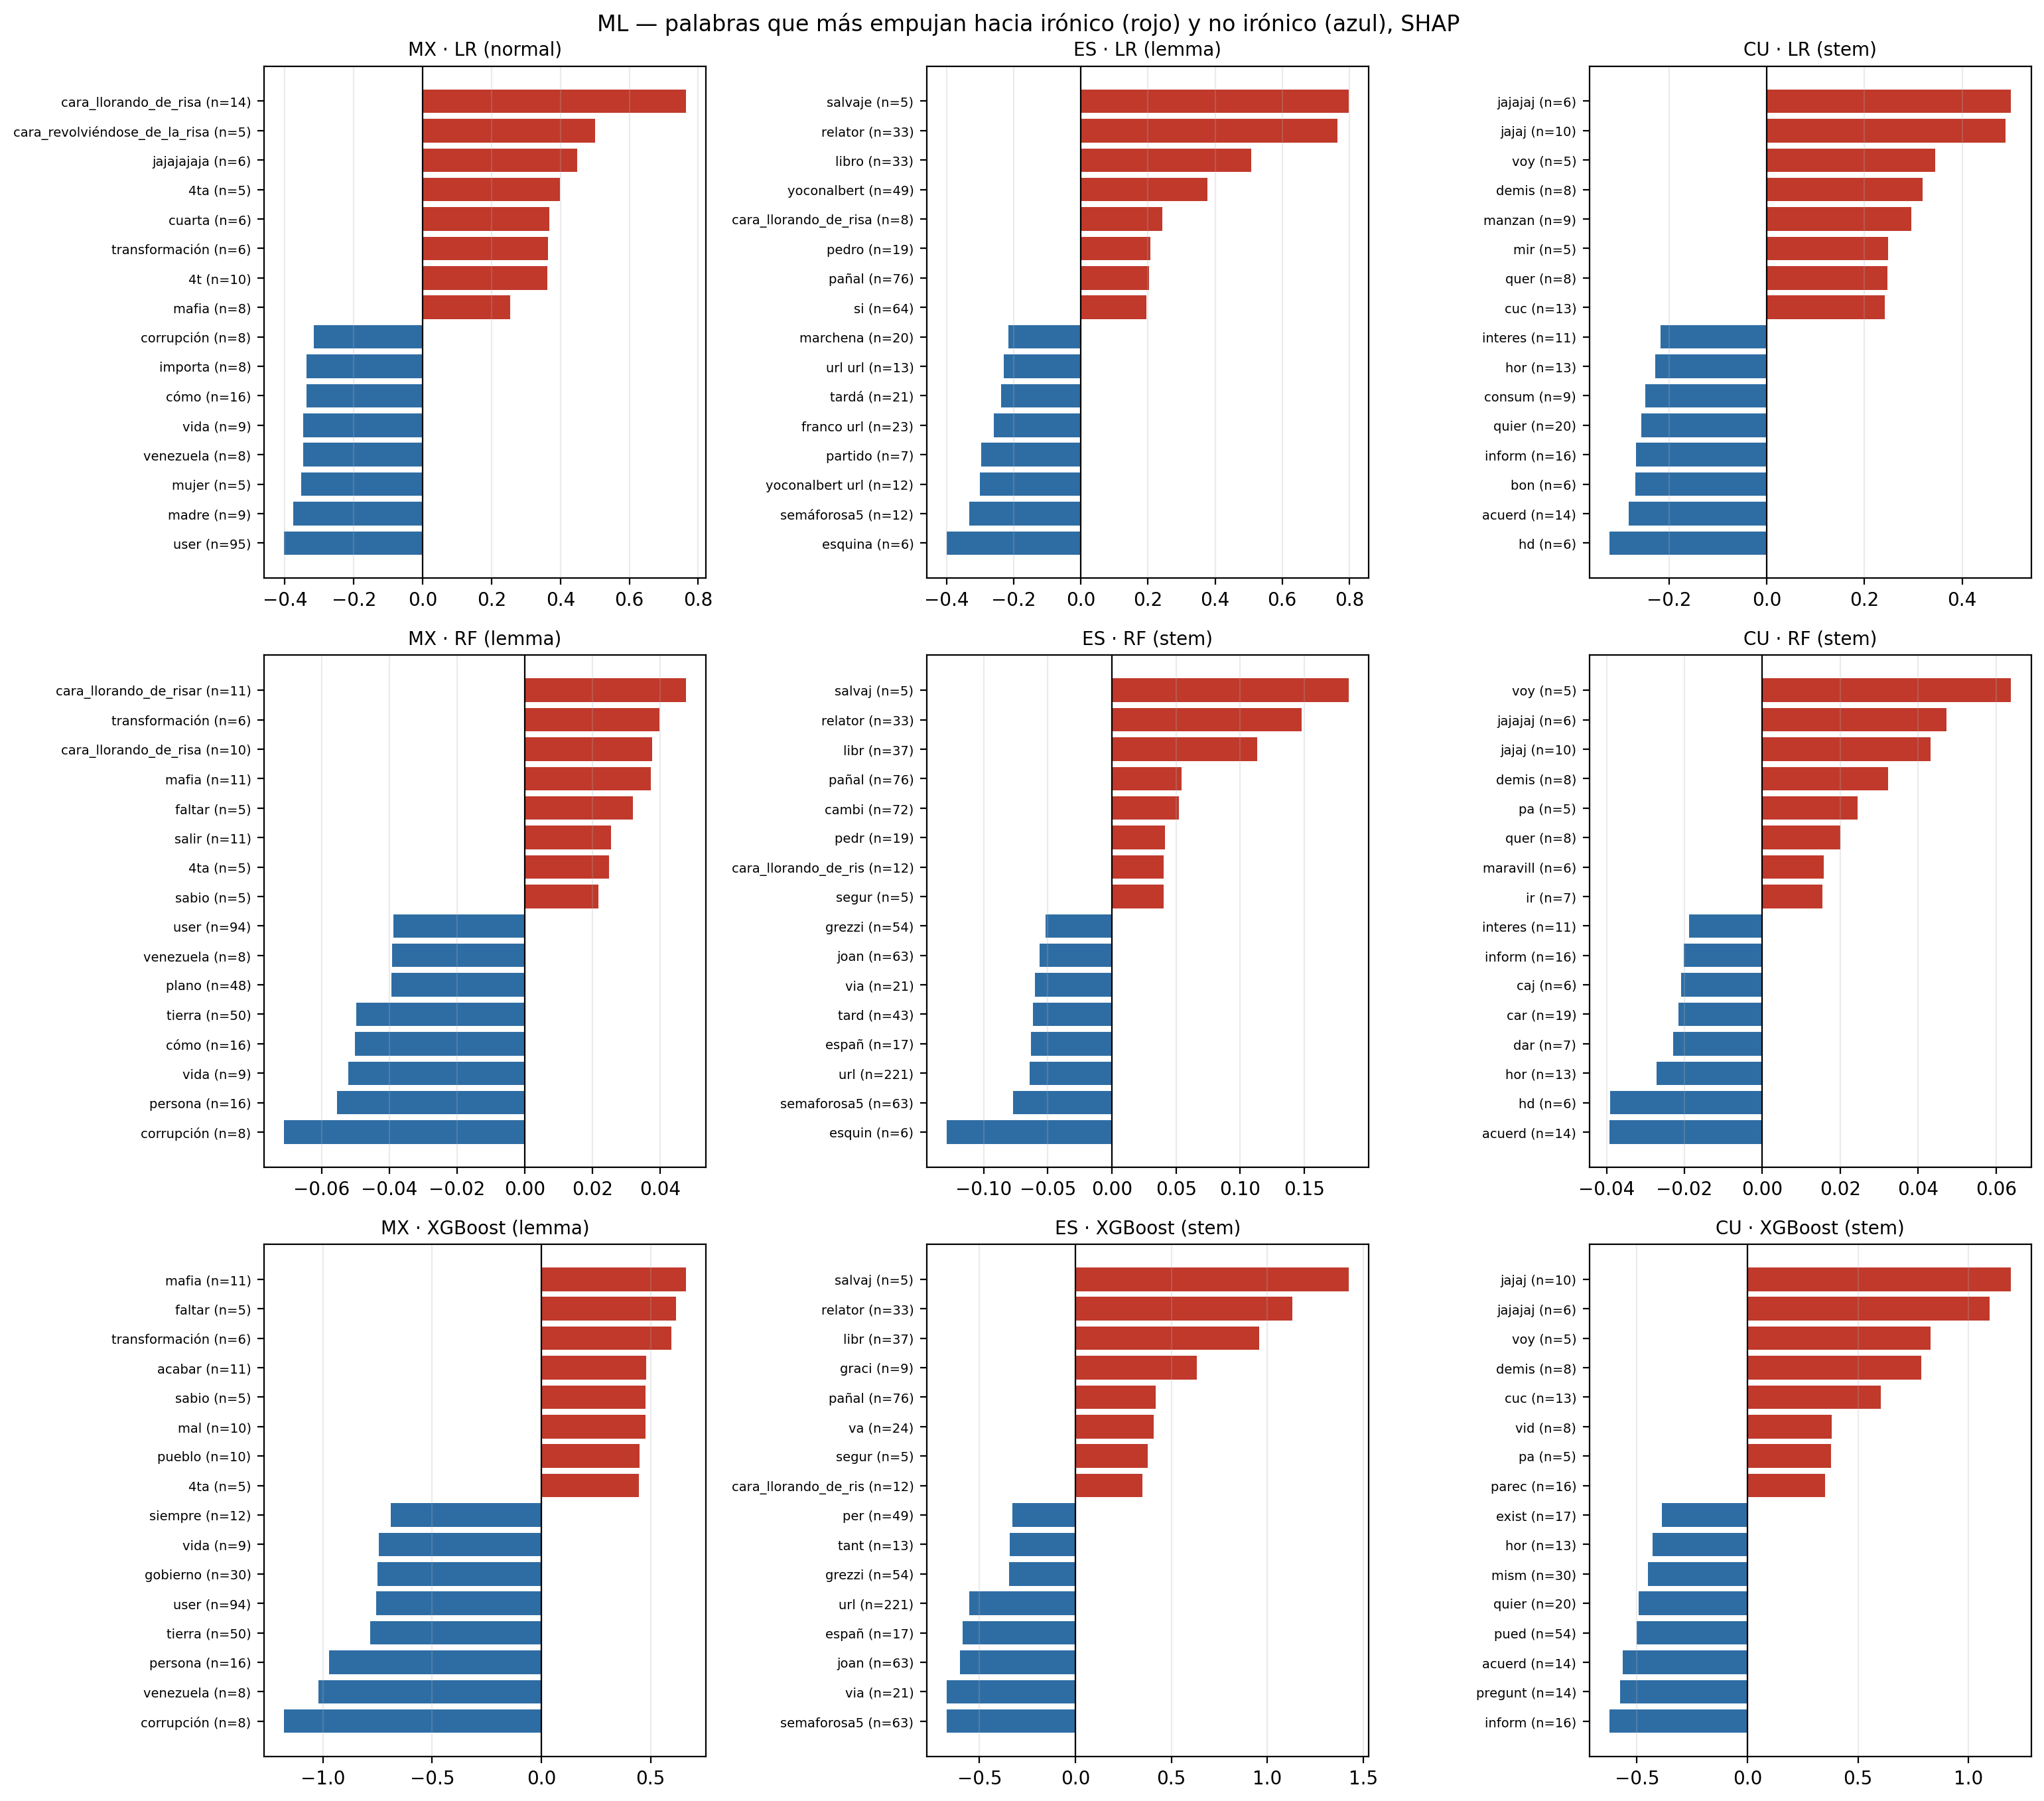

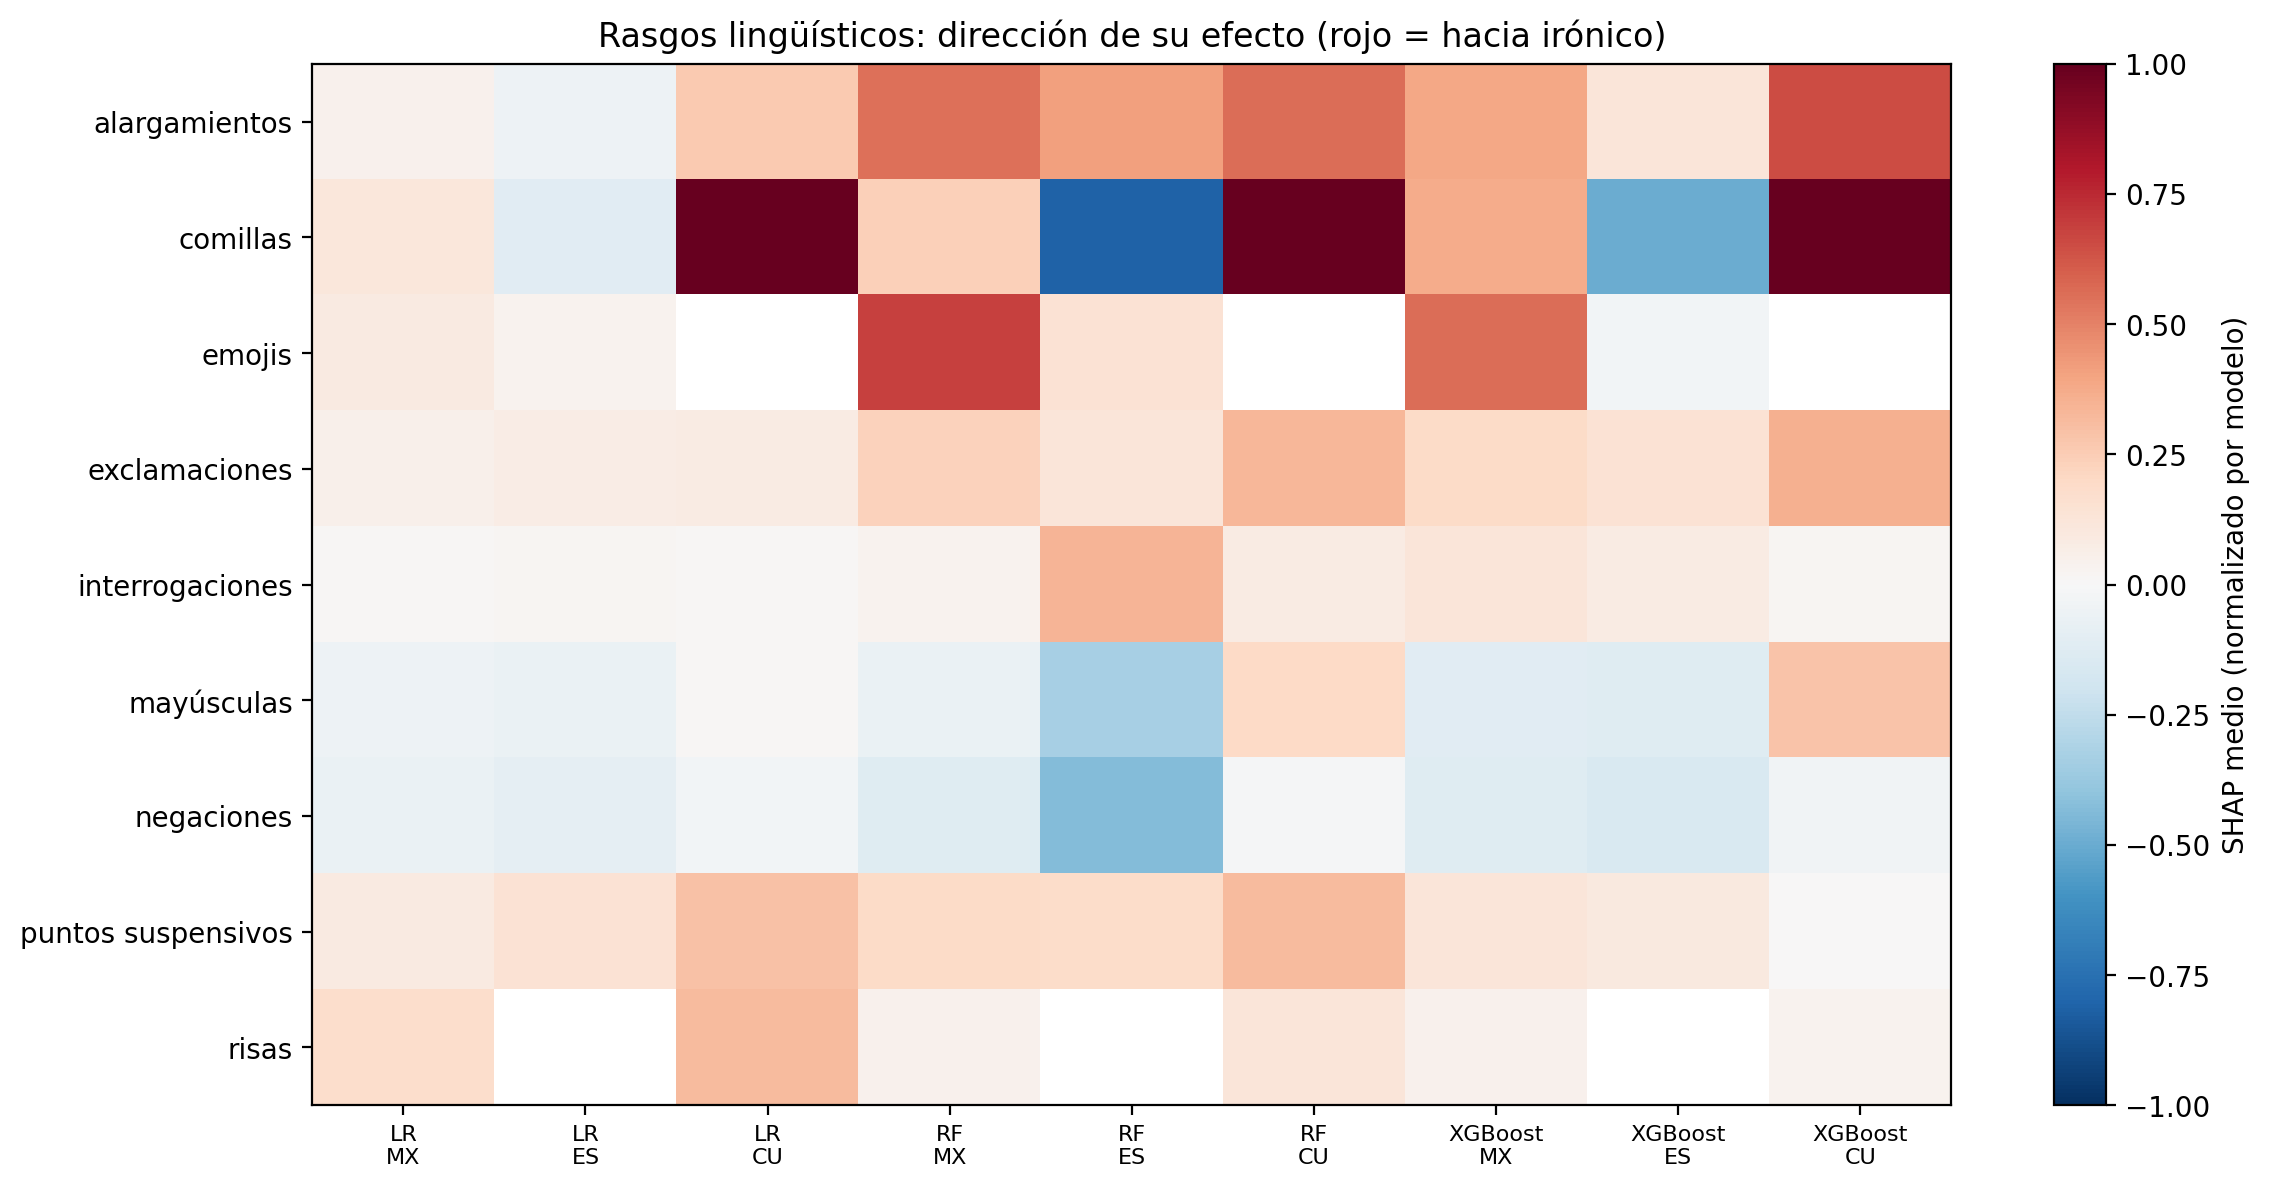

modelo                  LR                      RF                 XGBoost  \
variante                mx      es      cu      mx      es      cu      mx   
rasgo                                                                        
alargamientos       0.1203 -0.1533  0.8103  0.0293  0.0220  0.0299  0.4312   
comillas            0.3421 -0.3533  3.0742  0.0127 -0.0431  0.0532  0.4144   
emojis              0.2776  0.1178     NaN  0.0363  0.0078     NaN  0.6167   
exclamaciones       0.1645  0.2223  0.2431  0.0122  0.0064  0.0176  0.2089   
interrogaciones     0.0347  0.0683  0.0447  0.0018  0.0180  0.0043  0.1349   
mayúsculas         -0.1455 -0.1928  0.0367 -0.0034 -0.0176  0.0106 -0.1262   
negaciones         -0.2026 -0.2746 -0.0940 -0.0064 -0.0230 -0.0006 -0.1331   
puntos suspensivos  0.2796  0.4493  0.9019  0.0101  0.0100  0.0168  0.1343   
risas               0.5421     NaN  0.9790  0.0024     NaN  0.0064  0.0469   

modelo                              
variante                es      cu  
rasgo                               
alargamientos       0.1358  0.7254  
comillas           -0.5461  1.1057  
emojis             -0.0334     NaN  
exclamaciones       0.1571  0.3971  
interrogaciones     0.0875  0.0195  
mayúsculas         -0.1331  0.3196  
negaciones         -0.1722 -0.0363  
puntos suspensivos  0.1111  0.0000  
risas                  NaN  0.0350

In [31]:
if not EJECUTAR_TEST_OFICIAL:
    print("SHAP omitido: el test oficial está bloqueado.")
else:
    try:
        import shap
    except ImportError as exc:
        raise ImportError("Falta el paquete shap. Instálalo con:  py -m uv add shap") from exc
    import scipy.sparse as sp

    NOMBRES_RASGOS = {"n_exc": "exclamaciones", "n_int": "interrogaciones", "n_may": "mayúsculas", "n_emo": "emojis",
                      "n_ris": "risas", "n_neg": "negaciones", "n_elo": "alargamientos", "n_com": "comillas",
                      "n_pun": "puntos suspensivos"}


    def matriz(preproc, X):
        M = preproc.transform(X)
        return sp.csr_matrix(M, dtype=np.float64) if not sp.issparse(M) else M.tocsr().astype(np.float64)


    def contribuciones(modelo, estimador, X_train, X_test):
        preproc = estimador.named_steps["features"]
        clf = estimador.named_steps["xgb" if modelo == "XGBoost" else "clf"]
        nombres = preproc.get_feature_names_out()
        Mte = matriz(preproc, X_test)
        if modelo == "LR":
            media = np.asarray(matriz(preproc, X_train).mean(axis=0)).ravel()
            coef = clf.coef_.ravel()
            valores = Mte.toarray() * coef - media * coef
        elif modelo == "XGBoost":
            # SHAP exacto (TreeSHAP) calculado por el propio XGBoost: evita la
            # incompatibilidad de shap.TreeExplainer con XGBoost >= 3 (base_score).
            import xgboost as xgb
            dm = xgb.DMatrix(Mte)
            sv = clf.get_booster().predict(dm, pred_contribs=True, validate_features=False)
            valores = np.asarray(sv)[:, :-1]   # la última columna es el valor base
        else:
            # RF: TreeSHAP "interventional" con 100 tweets del train como referencia.
            # La variante por defecto (path-dependent) es numéricamente inestable con árboles muy
            # profundos (max_depth=None llega a ~200 niveles) y devuelve valores absurdos (~1e46).
            rng = np.random.RandomState(RANDOM_STATE)
            Mtr = matriz(preproc, X_train)
            fondo = Mtr[rng.choice(Mtr.shape[0], 100, replace=False)].toarray()
            explicador = shap.TreeExplainer(clf, data=fondo, feature_perturbation="interventional",
                                            model_output="probability")
            sv = explicador.shap_values(Mte.toarray(), check_additivity=False)
            sv = np.asarray(sv[1] if isinstance(sv, list) else sv)
            valores = sv[:, :, 1] if sv.ndim == 3 else sv
        valores = np.asarray(valores, dtype=np.float64)
        assert np.isfinite(valores).all() and np.abs(valores).max() < 1e3, f"SHAP fuera de rango en {modelo}"
        presente = (Mte != 0).toarray()
        return nombres, valores, presente


    def ids_test_en_train(variante):
        """Tweets del test que también están en el train: auditoría de los Transformers (si existe) + texto idéntico."""
        ids = set()
        for ruta in DATA_DIR.glob(f"resultados_*_grouped_5x3_tpe20/seguimiento/*/completo/audit/coincidencias_test_train_{variante}_*.csv"):
            ids |= set(pd.read_csv(ruta, dtype={"ID": str})["ID"].astype(str))
        colapsar = lambda s: s.astype(str).str.split().str.join(" ")
        tr, te = cargar_split(variante, "normal", "train"), cargar_split(variante, "normal", "test")
        ids |= set(te.loc[colapsar(te["MESSAGE"]).isin(set(colapsar(tr["MESSAGE"]))), "ID"].astype(str))
        return ids

    filas, filas_rasgos = [], []
    for variante in VARIANTES:
        X_tr_por_prep, _ = cargar_todos_preps(variante, split="train")
        for _, fila in df_seleccion_final[df_seleccion_final["variante"] == variante].iterrows():
            modelo, prep = fila["modelo"], fila["preprocessing"]
            est = MODELOS_FINALES[(variante, modelo)]
            df_te = cargar_split(variante, prep, split="test")
            df_te = df_te[~df_te["ID"].astype(str).isin(ids_test_en_train(variante))]  # sin tweets repetidos
            X_test, _ = preparar_xy(df_te)
            nombres, valores, presente = contribuciones(modelo, est, X_tr_por_prep[prep], X_test)
            for j, nombre in enumerate(nombres):
                tipo, termino = nombre.split("__", 1)
                if tipo == "linguisticas":
                    v = valores[presente[:, j], j]  # tuits donde el rasgo aparece (valor > 0)
                    filas_rasgos.append({"variante": variante, "modelo": modelo, "rasgo": NOMBRES_RASGOS.get(termino, termino),
                                         "n_textos": int(presente[:, j].sum()),
                                         "shap_medio": float(v.mean()) if len(v) else np.nan,
                                         "shap_abs_medio": float(np.abs(v).mean()) if len(v) else np.nan})
                    continue
                n = int(presente[:, j].sum())
                if n < MIN_TEXTOS_PALABRA:
                    continue
                v = valores[presente[:, j], j]  # contribución en los tuits donde aparece la palabra
                filas.append({"variante": variante, "modelo": modelo, "preprocessing": prep, "palabra": termino,
                              "n_textos": n, "shap_medio": float(v.mean()), "shap_abs_medio": float(np.abs(v).mean())})
            print(f"[{variante.upper()}][{modelo}] SHAP calculado ({prep})")

    SHAP_ML = pd.DataFrame(filas)
    SHAP_RASGOS = pd.DataFrame(filas_rasgos)
    SHAP_ML.to_csv(OUT_DIR / "ml_shap_global.csv", index=False)
    SHAP_RASGOS.to_csv(OUT_DIR / "ml_shap_rasgos.csv", index=False)

    fig, axes = plt.subplots(len(MODELOS_ML), len(VARIANTES), figsize=(5.2 * len(VARIANTES), 4.6 * len(MODELOS_ML)), squeeze=False)
    for i, modelo in enumerate(MODELOS_ML):
        for j, variante in enumerate(VARIANTES):
            ax = axes[i, j]
            g = SHAP_ML[(SHAP_ML["variante"] == variante) & (SHAP_ML["modelo"] == modelo)]
            sel = pd.concat([g.nlargest(TOP_PALABRAS, "shap_medio"), g.nsmallest(TOP_PALABRAS, "shap_medio")])
            sel = sel.drop_duplicates("palabra").sort_values("shap_medio")
            ax.barh(range(len(sel)), sel["shap_medio"], color=["#c0392b" if x > 0 else "#2e6da4" for x in sel["shap_medio"]])
            ax.set_yticks(range(len(sel)), [f"{p} (n={n})" for p, n in zip(sel["palabra"], sel["n_textos"])], fontsize=7)
            ax.axvline(0, color="black", lw=0.8)
            ax.grid(axis="x", alpha=0.25)
            prep = g["preprocessing"].iloc[0] if len(g) else ""
            ax.set_title(f"{variante.upper()} · {modelo} ({prep})", fontsize=10)
    fig.suptitle("ML — palabras que más empujan hacia irónico (rojo) y no irónico (azul), SHAP", fontsize=12)
    fig.tight_layout()
    fig.savefig(OUT_DIR / "ml_shap_palabras.png", dpi=200, bbox_inches="tight")
    fig.savefig(OUT_DIR / "ml_shap_palabras.pdf", bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(OUT_DIR / "ml_shap_palabras.png")))

    tabla = SHAP_RASGOS.pivot_table(index="rasgo", columns=["modelo", "variante"], values="shap_medio")
    tabla = tabla.reindex(columns=[(m, v) for m in MODELOS_ML for v in VARIANTES])
    fig, ax = plt.subplots(figsize=(1.0 * tabla.shape[1] + 3, 0.45 * tabla.shape[0] + 2))
    # Normalización por modelo (escalas distintas): se divide por el máximo |valor| de cada modelo.
    norm = tabla.copy()
    for m in MODELOS_ML:
        cols = [c for c in norm.columns if c[0] == m]
        escala = np.nanmax(np.abs(norm[cols].to_numpy())) or 1.0
        norm[cols] = norm[cols] / escala
    im = ax.imshow(norm.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(tabla.shape[1]), [f"{m}\n{v.upper()}" for m, v in tabla.columns], fontsize=8)
    ax.set_yticks(range(tabla.shape[0]), tabla.index)
    fig.colorbar(im, ax=ax, label="SHAP medio (normalizado por modelo)")
    ax.set_title("Rasgos lingüísticos: dirección de su efecto (rojo = hacia irónico)")
    fig.tight_layout()
    fig.savefig(OUT_DIR / "ml_shap_rasgos.png", dpi=200, bbox_inches="tight")
    fig.savefig(OUT_DIR / "ml_shap_rasgos.pdf", bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(OUT_DIR / "ml_shap_rasgos.png")))
    display(tabla.round(4))

### 11.1 Ejemplos locales (VP, FP y FN)

El análisis anterior es **global** (qué palabras pesan en general). Aquí se muestra el análisis **local**: para cada variante se toma el **mejor modelo de ML según la Nested CV** y se explican tres tweets del test, los mismos tipos que en los Transformers: el verdadero positivo y el falso positivo con **mayor** probabilidad de ironía y el falso negativo con **menor** probabilidad (los casos en que el modelo estuvo más seguro). Se excluyen los tweets del test que también están en el train.

Cada barra es una palabra del tweet (o un rasgo lingüístico, entre corchetes) con su contribución SHAP: rojo empuja hacia *irónico*, azul hacia *no irónico*. Como el TF-IDF no conserva el orden de las palabras, se ordenan por contribución absoluta; con `MAX_PALABRAS_EJEMPLO = None` se muestran todas las palabras y rasgos presentes en el tweet (con un número se muestran solo esas). Archivos: `ml_shap_ejemplos.png/.pdf` y `ml_shap_ejemplos.csv`.

Mejor modelo de ML por variante (Nested CV): {'mx': 'LR', 'es': 'LR', 'cu': 'RF'}


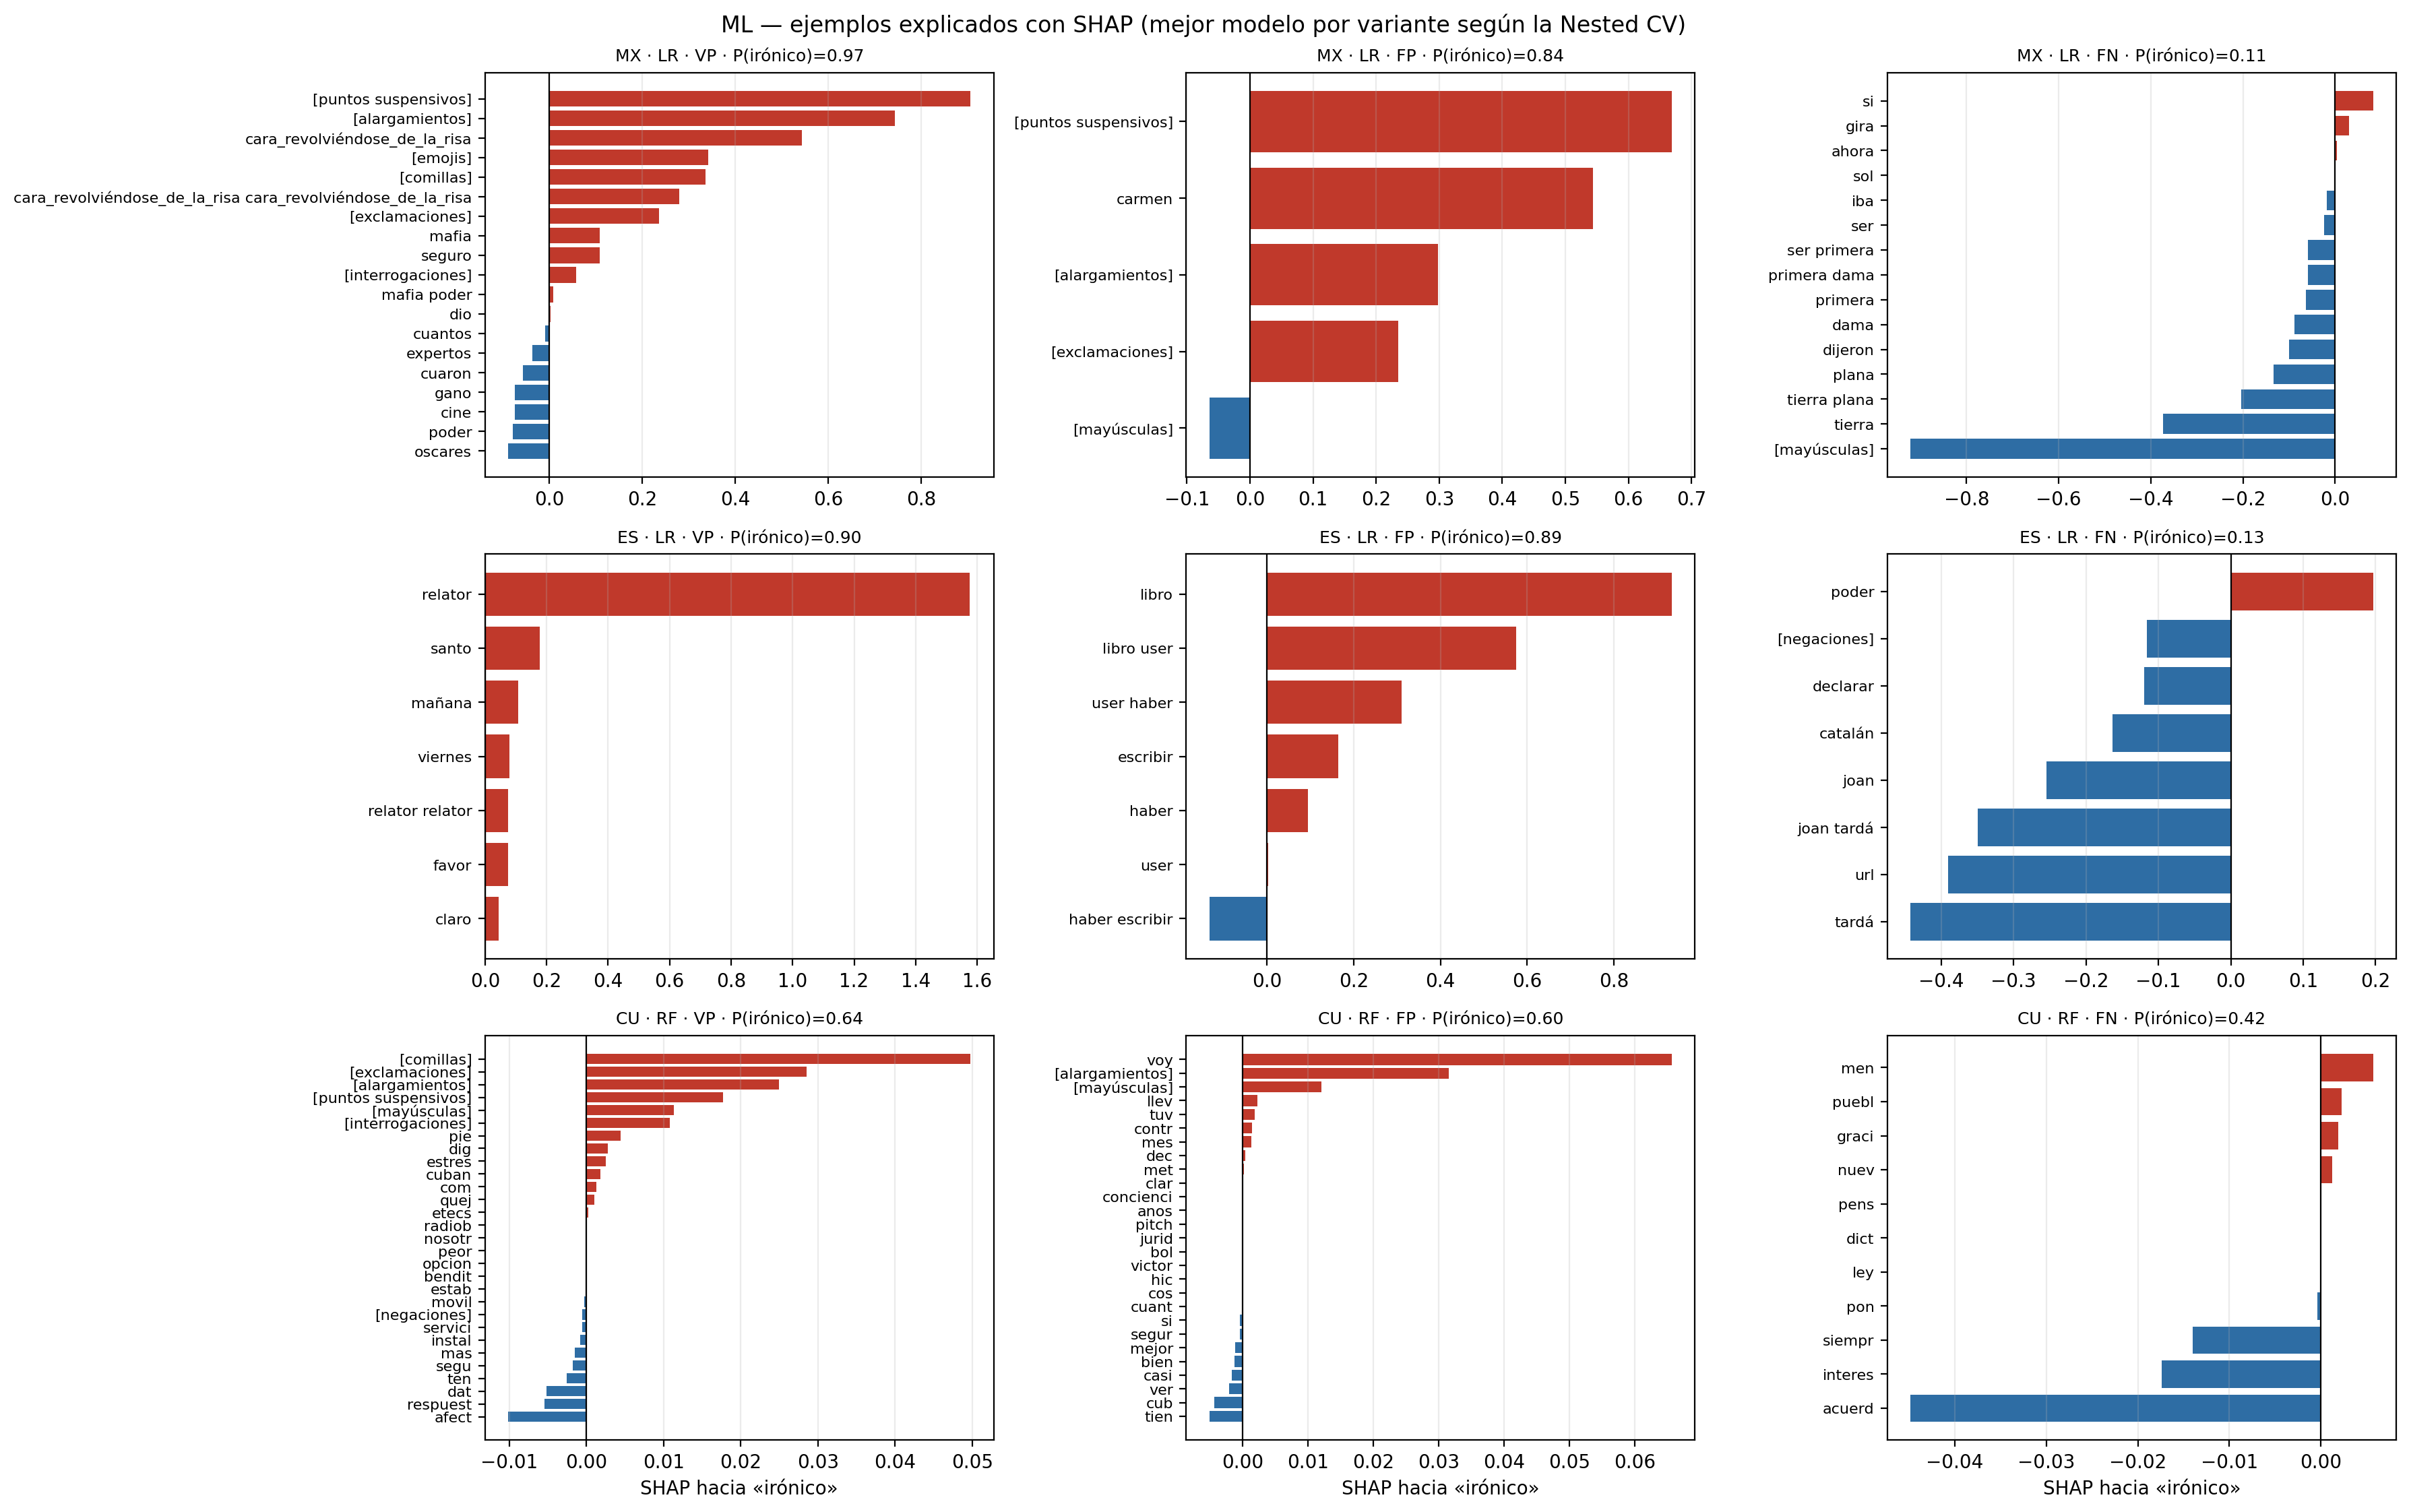

,variante,modelo,tipo,prob_ironia,mensaje_original
0,mx,LR,VP,0.966829,"Eskiusmy... Cuantos Oscares han ganado estos ""Expertos"" en Cine??? Miren... Cuaron gano 3... Seguro, se los dio la mafia de poder de Jolibud... Joder!!! 🤣🤣🤣"
1,mx,LR,FP,0.844874,Carmen .......... Alfonso UN FUERTE ABRAZO!!!
2,mx,LR,FN,0.110047,"SI DIJERON QUE UNA CON DOGTORADO IBA A SER PRIMERA DAMA, LA CAMBIARON. MAMADO NERVO Y EL SOL GIRA ALREDEDOR DE LA TIERRA LA ENTERRARON. APRENDERÉ AHORA QUE LA TIERRA ES PLANA"
3,es,LR,VP,0.903999,"Yo muy a favor del Relator, de Relator con Parras, el Viernes Santo por la mañana, claro."
4,es,LR,FP,0.888017,El libro de @sanchezcastejon lo ha escrito @vini11Oficial
5,es,LR,FN,0.132104,Joan Tardá no puede declarar en Catalán. Guardiola de morritos. https://t.co/JPLmO96dX4
6,cu,RF,VP,0.637283,"el servicio de datos móviles está PEOR que como estaba antes de instalar la bendita radiobase.. ¿a quién quejarse?... ¡No hay respuesta! ¿Quiénes son los más afectados? ¡Nosotros! Los cubanos de ""a pie"" que no tenemos otra opción que seguir con ""estresa"", digo, con etecsa."
7,cu,RF,FP,0.600468,Te voy a decir una cosa Edemis lo que tu hiciste si lo llevamos a la conciencia juridica te meten una bola de anos\r\nen cuanto al mejor pitcher de Cuba esta bien claro que tienes algo contra el RRRRRRAAAAAATTTTTTOOOOOONNNNNN eSTOY CASI SEGURO QUE Victor Mesa tuvo algo que ver ..
8,cu,RF,FN,0.416418,gracias nuevamente por pensar en los intereses del pueblo ..siempre que dictan una ley con el que menos se ponen de acuerdo ..


In [32]:
if not EJECUTAR_TEST_OFICIAL:
    print("SHAP omitido: el test oficial está bloqueado.")
else:
    MAX_PALABRAS_EJEMPLO = None
    EJEMPLOS = [("VP", False), ("FP", False), ("FN", True)]

    def nombre_legible(nombre):
        tipo, termino = nombre.split("__", 1)
        return f"[{NOMBRES_RASGOS.get(termino, termino)}]" if tipo == "linguisticas" else termino

    MEJOR_ML = {
        v: df_nested_comparativo[df_nested_comparativo["variante"] == v]
        .sort_values("f1_nested_mean", ascending=False).iloc[0]["modelo"]
        for v in VARIANTES
    }
    print("Mejor modelo de ML por variante (Nested CV):", MEJOR_ML)

    fig, axes = plt.subplots(len(VARIANTES), len(EJEMPLOS), figsize=(6.0 * len(EJEMPLOS), 3.8 * len(VARIANTES)), squeeze=False)
    filas_ej = []
    for i, variante in enumerate(VARIANTES):
        modelo = MEJOR_ML[variante]
        fila_sel = df_seleccion_final[(df_seleccion_final["variante"] == variante) & (df_seleccion_final["modelo"] == modelo)].iloc[0]
        prep = fila_sel["preprocessing"]
        est = MODELOS_FINALES[(variante, modelo)]
        X_tr_por_prep, _ = cargar_todos_preps(variante, split="train")
        df_test = cargar_split(variante, prep, split="test")
        X_test, y_test = preparar_xy(df_test)
        y_test = y_test.to_numpy()
        prob = est.predict_proba(X_test)[:, 1]
        pred = est.predict(X_test).astype(int)
        tipo = np.select([(y_test == 1) & (pred == 1), (y_test == 0) & (pred == 0), (y_test == 0) & (pred == 1)], ["VP", "VN", "FP"], "FN")
        valido = ~df_test["ID"].astype(str).isin(ids_test_en_train(variante)).to_numpy()
        nombres, valores, presente = contribuciones(modelo, est, X_tr_por_prep[prep], X_test)
        for j, (t, ascendente) in enumerate(EJEMPLOS):
            ax = axes[i, j]
            cand = np.where((tipo == t) & valido)[0]
            if len(cand) == 0:
                ax.axis("off")
                continue
            k = cand[np.argsort(prob[cand])][0 if ascendente else -1]
            idx = np.where(presente[k])[0]
            orden = idx[np.argsort(-np.abs(valores[k, idx]))][:MAX_PALABRAS_EJEMPLO]
            orden = orden[np.argsort(valores[k, orden])]
            etiquetas = [nombre_legible(nombres[c]) for c in orden]
            ax.barh(range(len(orden)), valores[k, orden], color=["#c0392b" if x > 0 else "#2e6da4" for x in valores[k, orden]])
            ax.set_yticks(range(len(orden)), etiquetas, fontsize=8)
            ax.axvline(0, color="black", lw=0.8)
            ax.grid(axis="x", alpha=0.25)
            ax.set_title(f"{variante.upper()} · {modelo} · {t} · P(irónico)={prob[k]:.2f}", fontsize=9)
            if i == len(VARIANTES) - 1:
                ax.set_xlabel("SHAP hacia «irónico»")
            filas_ej.append({
                "variante": variante, "modelo": modelo, "preprocessing": prep, "tipo": t,
                "ID": str(df_test["ID"].iloc[k]), "prob_ironia": float(prob[k]),
                "mensaje_original": str(df_test["MESSAGE"].iloc[k]) if "MESSAGE" in df_test else "",
                "contribuciones": "; ".join(f"{e}={valores[k, c]:+.3f}" for e, c in zip(etiquetas[::-1], orden[::-1])),
            })
    fig.suptitle("ML — ejemplos explicados con SHAP (mejor modelo por variante según la Nested CV)", fontsize=12)
    fig.tight_layout()
    fig.savefig(OUT_DIR / "ml_shap_ejemplos.png", dpi=200, bbox_inches="tight")
    fig.savefig(OUT_DIR / "ml_shap_ejemplos.pdf", bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(OUT_DIR / "ml_shap_ejemplos.png")))
    EJEMPLOS_ML = pd.DataFrame(filas_ej)
    EJEMPLOS_ML.to_csv(OUT_DIR / "ml_shap_ejemplos.csv", index=False)
    with pd.option_context("display.max_colwidth", None):
        display(EJEMPLOS_ML[["variante", "modelo", "tipo", "prob_ironia", "mensaje_original"]])

## 12. Resumen metodológico

1. Los Outer e Inner folds están **agrupados**; no se comparte entre train/validación ningún grupo conectado por coincidencia textual (tras `casefold`/`strip`) en `normal`, `stem`, `lemma` o mensaje original.
2. La validación utiliza **5 Outer × 3 Inner** con `StratifiedGroupKFold`; la búsqueda final sobre todo el train usa 3 folds agrupados.
3. El control de duplicados exactos y de conflictos de etiqueta se hizo una sola vez, solo dentro del train, en `01_preprocesamiento_ML.ipynb`. El train no se modifica. Los tweets del test que también aparecen en el train se excluyen del resultado principal en `06_Comparacion_final.ipynb`, que reporta además el F1 con el test completo (análisis de sensibilidad).
4. Los grupos con etiquetas mixtas se mantienen completos en un único fold y se registran en `auditoria_etiquetas_contradictorias.csv` como posible ruido/ambigüedad de anotación.
5. `F1 Train`, `F1 Outer`, resultados OOF, F1 por clase y resultados por Outer Fold se calculan sobre el procedimiento agrupado. Las comparaciones entre modelos son descriptivas.
6. El test oficial se evaluó una sola vez, al final, con todas las decisiones ya tomadas.
7. Este notebook corresponde al perfil TF-IDF de 10 000 términos. Una comparación con otro perfil (por ejemplo, 20k) solo es válida si usa el mismo dataset final, grupos, semillas, clasificadores y protocolo 5×3, variando únicamente el TF-IDF.
8. En el test, cada modelo final se evaluó con 5 semillas (42, 52, 62, 72, 82) sin cambiar hiperparámetros; se reporta media ± desviación. LR (`liblinear`) es determinista.
9. SHAP explica los modelos de la semilla 42 sobre el test sin usar etiquetas; no interviene en ninguna decisión.

**Referencias de interpretabilidad:** Lundberg, S. M., y Lee, S.-I. (2017). A unified approach to interpreting model predictions. *NeurIPS*. — Lundberg, S. M., et al. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence, 2*, 56–67.